# UE Data Mining - Projet : jeu de données `health/`

* Nom du groupe : Groupe 10
* Membres du groupe :
    * Prénom NOM
    * Prénom NOM

On a choisi le dossier `data/health/` (7 fichiers : patients, consultations, observations, procédures, notes cliniques, enregistrements cardiaques et leurs signaux).

Le notebook suit l'ordre des cours : à chaque cours on a repris le code et ajouté les nouvelles méthodes.

| Partie | Cours | Contenu |
|---|---|---|
| 0 à 6 | Cours 1 | nettoyage, création de variables, statistiques, histogrammes / boxplots / barplots, corrélations |
| 6 à 12 | Cours 2 | préparation (échelles, one-hot), PCA, t-SNE, K-means, DBSCAN, clustering agglomératif |
| 13 et 14 | Cours 3 | patterns (co-occurrences, Apriori) et anomalies (IQR, z-score, DBSCAN, Isolation Forest, LOF) |
| 15 et 16 | Cours 4 | graphe (centralités, communautés de Louvain) et process mining (Heuristic Miner) |
| 17 et 18 | Cours 5 | données spatiales (régions, établissements) et temporelles (décomposition, ACF, fenêtre glissante) |
| 19 | Cours 6 | notes cliniques : pré-traitement, sac de mots, n-grammes, TF-IDF, LSA, LDA |
| 20 | | Conclusion |

Les parties 0 à 12 sont regroupées dans une seule fonction `run_pipeline()` (lecture -> nettoyage -> variables -> stats -> préparation -> clustering -> sauvegarde). Les parties suivantes repartent de son résultat `res`.

## 0. Imports et réglages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# ajoutés pour les cours 2 à 6
import re
from itertools import combinations
from collections import Counter
import networkx as nx
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation

# Dossier qui contient les 7 CSV d'origine (chemin depuis le dossier où se trouve le notebook)
DOSSIER = "data/health"

# Dossier où seront écrits les fichiers nettoyés (les CSV d'origine ne sont JAMAIS modifiés)
DOSSIER_SORTIE = "data/health_clean"

# Graine aléatoire : on obtient les mêmes résultats à chaque exécution
SEED = 42

# Deux variables sont "redondantes" si |Spearman| dépasse ce seuil (cours 2, slide 12)
SEUIL_CORR = 0.90

# Poids des colonnes one-hot : plus petit que 1 pour qu'elles ne dominent pas la distance
POIDS_ONEHOT = 0.5

# Une mesure clinique devient une variable seulement si au moins 50 % des patients l'ont
COUVERTURE_MIN = 0.5

# Formats de dates rencontrés dans les fichiers (le 1er est le format voulu au final)
FORMATS_DATES = [
    "%Y-%m-%dT%H:%M:%S", "%Y-%m-%d",
    "%Y/%m/%d %H:%M:%S", "%Y/%m/%d",
    "%d/%m/%Y %H:%M:%S", "%d/%m/%Y",
    "%d-%b-%Y %H:%M:%S", "%d-%b-%Y",
]

## 1. Petites fonctions de nettoyage (utilisées par toutes les tables)
* `nettoyer_texte` : enlève les espaces en trop et met tout en minuscules (`"  Specialist  review "` = `"specialist review"`).
* `nettoyer_dates` : une colonne de dates écrites de plusieurs façons → un seul format.
* `nettoyer_nombre` : `"77.4 bpm"` ou `"84,9"` → `77.4` et `84.9`.
* `supprimer_doublons` : enlève les lignes strictement identiques.

In [2]:
def nettoyer_texte(serie):
    """Enlève les espaces en trop et met en minuscules."""
    return serie.str.strip().str.replace(r"\s+", " ", regex=True).str.lower()


def nettoyer_dates(serie):
    """Convertit des dates écrites sous plusieurs formats en un seul type datetime."""
    resultat = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")
    for fmt in FORMATS_DATES:
        # on essaie chaque format sur ce qui n'a pas encore été converti
        resultat = resultat.fillna(pd.to_datetime(serie, format=fmt, errors="coerce"))
    return resultat


def nettoyer_nombre(serie):
    """Garde seulement le nombre : '77.4 bpm' -> 77.4 ; '84,9' -> 84.9."""
    nombre = serie.str.extract(r"^\s*(-?\d+(?:[.,]\d+)?)")[0]
    return pd.to_numeric(nombre.str.replace(",", "."), errors="coerce").astype("float64")


def supprimer_doublons(df, nom):
    """Supprime les lignes dupliquées et affiche combien il y en avait."""
    n = df.duplicated().sum()
    print(f"  {nom} : {n} doublon(s) supprimé(s)")
    return df.drop_duplicates().reset_index(drop=True)

## 2. Nettoyage table par table

**Ce qu'on a trouvé en explorant les fichiers :**

| Table | Problèmes |
|---|---|
| patients | 1 doublon, `"vALENNE rEPUBLIC"` et `"ACTIVE"` (casse), 2 dates d'inscription dans un autre format |
| consultations | 2 doublons, casse mélangée (`TECHNICAL_REPEAT`…), espaces doubles, 5 dates dans un autre format, 3 `referral_source` vides |
| observations | 2 doublons, valeurs écrites `"84,9"` ou `"77.4 bpm"`, 2 écritures du même nom, casse, `device_reference` vide (4 326) |
| procédures | 1 doublon, casse, espaces doubles, 3 dates dans un autre format, `material_reference` vide (261) |
| notes | colonne `superseded_document_id` vide à 100 % |
| enregistrements / signaux | propres (on vérifie juste la cohérence) |

**Manquants :** quand le vide a un sens (ex. pas de matériel utilisé), on le remplace par une modalité (`no_material`, `unknown`) plutôt que de supprimer la ligne.
`follow_up_date` est vide pour la **dernière** consultation de chaque patient : il n'y a pas de suivi prévu, ce n'est pas une erreur. On garde le vide et on ajoute une colonne 0/1.

In [3]:
def nettoyer_patients(df):
    df["registered_sex"] = nettoyer_texte(df["registered_sex"])
    df["record_status"] = nettoyer_texte(df["record_status"])
    df["home_region"] = nettoyer_texte(df["home_region"])
    df["occupation_text"] = nettoyer_texte(df["occupation_text"])
    df["date_of_birth"] = nettoyer_dates(df["date_of_birth"])
    df["registration_date"] = nettoyer_dates(df["registration_date"])
    return supprimer_doublons(df, "patients")


def nettoyer_consultations(df):
    for col in ["encounter_type", "referral_source", "service_unit", "disposition", "confidentiality_class"]:
        df[col] = nettoyer_texte(df[col])
    for col in ["encounter_start", "encounter_end", "follow_up_date"]:
        df[col] = nettoyer_dates(df[col])
    df["referral_source"] = df["referral_source"].fillna("unknown")
    df = supprimer_doublons(df, "consultations")
    # variables calculées
    df["duration_min"] = (df["encounter_end"] - df["encounter_start"]).dt.total_seconds() / 60
    df["has_follow_up"] = df["follow_up_date"].notna().astype(int)
    return df


def nettoyer_observations(df):
    df["observation_name"] = df["observation_name"].str.strip().str.replace(r"\s+", " ", regex=True)
    for col in ["interpretation_code", "quality_code", "text_value"]:
        df[col] = nettoyer_texte(df[col])
    df["observation_time"] = nettoyer_dates(df["observation_time"])
    df["numeric_value"] = nettoyer_nombre(df["numeric_value"])
    # un seul nom par code : on garde le plus fréquent
    nom_par_code = df.groupby("observation_code")["observation_name"].agg(lambda s: s.mode()[0])
    df["observation_name"] = df["observation_code"].map(nom_par_code)
    df["device_reference"] = df["device_reference"].fillna("unknown")
    # valeur hors de la plage de référence : on la GARDE mais on la signale (ce n'est pas une erreur)
    plage = df["reference_range_text"].str.extract(r"^\s*(-?\d*\.?\d+)\s*–\s*(-?\d*\.?\d+)\s*$").apply(pd.to_numeric).astype("float64")
    df["hors_plage"] = ((df["numeric_value"] < plage[0]) | (df["numeric_value"] > plage[1])).astype(int)
    return supprimer_doublons(df, "observations")


def nettoyer_procedures(df):
    df["procedure_description"] = df["procedure_description"].str.strip().str.replace(r"\s+", " ", regex=True)
    for col in ["authorization_class", "outcome_code"]:
        df[col] = nettoyer_texte(df[col])
    for col in ["scheduled_time", "performed_time", "next_review_date"]:
        df[col] = nettoyer_dates(df[col])
    df["material_reference"] = df["material_reference"].fillna("no_material")
    return supprimer_doublons(df, "procédures")


def nettoyer_notes(df):
    df["document_type"] = nettoyer_texte(df["document_type"])
    df["confidentiality_class"] = nettoyer_texte(df["confidentiality_class"])
    df["document_date"] = nettoyer_dates(df["document_date"])
    # colonne entièrement vide : aucune information, on la supprime
    colonnes_vides = [c for c in df.columns if df[c].isna().all()]
    print(f"  notes : colonnes vides supprimées {colonnes_vides}")
    return df.drop(columns=colonnes_vides)


def nettoyer_enregistrements(df):
    for col in ["recording_context", "automated_interpretation", "recording_notes_code"]:
        df[col] = nettoyer_texte(df[col])
    df["recording_date"] = nettoyer_dates(df["recording_date"])
    for col in ["sampling_rate_hz", "duration_seconds", "sample_count", "device_quality"]:
        df[col] = pd.to_numeric(df[col])
    return supprimer_doublons(df, "enregistrements")

## 3. Lecture et nettoyage de tous les fichiers

In [4]:
def charger_et_nettoyer(dossier=DOSSIER):
    """Lit les 7 CSV (en texte, pour ne pas laisser pandas deviner) puis les nettoie."""
    if not os.path.exists(f"{dossier}/patient_administration.csv"):
        raise FileNotFoundError(f"Je ne trouve pas les CSV dans '{dossier}'. Dossier courant : {os.getcwd()}")
    lire = lambda nom: pd.read_csv(f"{dossier}/{nom}.csv", dtype="string")
    tables = {
        "patients": nettoyer_patients(lire("patient_administration")),
        "consultations": nettoyer_consultations(lire("clinical_encounters")),
        "observations": nettoyer_observations(lire("clinical_observations")),
        "procedures": nettoyer_procedures(lire("clinical_procedures")),
        "notes": nettoyer_notes(lire("clinical_notes")),
        "enregistrements": nettoyer_enregistrements(lire("cardiac_recordings")),
        # les signaux sont déjà numériques et propres : lecture directe
        "signaux": pd.read_csv(f"{dossier}/cardiac_signal_samples.csv"),
    }
    # vérification simple : aucune clé orpheline entre les tables
    c = tables["consultations"]
    assert c["patient_number"].isin(tables["patients"]["patient_number"]).all()
    assert tables["observations"]["encounter_number"].isin(c["encounter_number"]).all()
    assert tables["procedures"]["encounter_number"].isin(c["encounter_number"]).all()
    assert tables["signaux"]["recording_id"].isin(tables["enregistrements"]["recording_id"]).all()
    return tables

## 4. Créer des variables
Pour comparer des patients (cours 2 : « proches ou éloignés ? »), il faut **une ligne par patient**. On résume donc les autres tables.

* **Mesures cliniques** (pouls, tension…) : on prend la **médiane** par patient, plus robuste que la moyenne (cours 1, slide 13-14 : beaucoup de variables suivent une loi de puissance).
* **Comptages** (nombre de consultations, de procédures…) : variables discrètes.
* **Âge** : âge à la dernière consultation. `bioage_gap` = âge biologique estimé − âge réel (variable calculée).

Pour les **signaux cardiaques** (1 200 à 3 750 points par enregistrement), on les résume avec quelques chiffres : moyenne, écart-type, amplitude, kurtosis, fréquence dominante (FFT) et corrélation entre les deux canaux.

In [5]:
def variables_patients(t):
    """Renvoie un tableau avec une ligne par patient."""
    p, c, o, r, rec = t["patients"], t["consultations"], t["observations"], t["procedures"], t["enregistrements"]
    f = p.set_index("patient_number")[["registered_sex", "home_region", "primary_facility_license"]].copy()
    par_patient = c.groupby("patient_number")

    # âge à la dernière consultation et durée de suivi
    derniere = par_patient["encounter_start"].max()
    premiere = par_patient["encounter_start"].min()
    naissance = p.set_index("patient_number")["date_of_birth"]
    f["age"] = (derniere - naissance).dt.days / 365.25
    f["follow_years"] = (derniere - premiere).dt.days / 365.25
    f["mean_encounter_min"] = par_patient["duration_min"].mean()
    f["share_confidential"] = (c["confidentiality_class"] != "standard").groupby(c["patient_number"]).mean()

    # comptages (0 si le patient n'apparaît pas dans la table)
    f["n_encounters"] = par_patient.size()
    f["n_procedures"] = r.groupby("patient_number").size()
    f["n_recordings"] = rec.groupby("patient_number").size()
    f["n_discordant"] = (o["interpretation_code"] == "discordant").groupby(o["patient_number"]).sum()
    for col in ["n_procedures", "n_recordings", "n_discordant"]:
        f[col] = f[col].fillna(0)

    # variables binaires
    restreint = r["authorization_class"].isin(["restricted_specialist", "research_restricted"])
    f["has_restricted_procedure"] = restreint.groupby(r["patient_number"]).any().reindex(f.index, fill_value=False).astype(int)
    f["is_deceased"] = (p.set_index("patient_number")["record_status"] == "deceased").astype(int)

    # médiane des mesures numériques, pour les mesures présentes chez assez de patients
    mesures = o.dropna(subset=["numeric_value"]).pivot_table(
        index="patient_number", columns="observation_code", values="numeric_value", aggfunc="median")
    mesures = mesures.loc[:, mesures.notna().mean() >= COUVERTURE_MIN].add_prefix("obs_")
    f = f.join(mesures)
    f["bioage_gap"] = f["obs_BIOAGE"] - f["age"]

    groupes = {
        "continues": ["age", "bioage_gap", "follow_years", "mean_encounter_min", "share_confidential"] + list(mesures.columns),
        "comptages": ["n_encounters", "n_procedures", "n_recordings", "n_discordant"],
        "binaires": ["has_restricted_procedure", "is_deceased"],
        "categories": ["registered_sex", "home_region", "primary_facility_license"],
    }
    return f, groupes


def variables_enregistrements(t):
    """Renvoie un tableau avec une ligne par enregistrement cardiaque (résumé du signal)."""
    lignes = []
    freq = t["enregistrements"].set_index("recording_id")["sampling_rate_hz"]
    for rec_id, g in t["signaux"].groupby("recording_id"):
        ligne = {"recording_id": rec_id}
        for canal in ["a", "b"]:
            x = g[f"channel_{canal}_normalized"].to_numpy()
            spectre = np.abs(np.fft.rfft(x - x.mean()))
            freqs = np.fft.rfftfreq(len(x), d=1 / freq[rec_id])
            ligne[f"{canal}_mean"] = x.mean()
            ligne[f"{canal}_std"] = x.std()
            ligne[f"{canal}_range"] = x.max() - x.min()
            ligne[f"{canal}_kurtosis"] = kurtosis(x)
            ligne[f"{canal}_freq_dominante"] = freqs[1:][spectre[1:].argmax()]   # on ignore la fréquence 0
        ligne["correlation_ab"] = np.corrcoef(g["channel_a_normalized"], g["channel_b_normalized"])[0, 1]
        lignes.append(ligne)
    f = pd.DataFrame(lignes).set_index("recording_id")
    f["device_quality"] = t["enregistrements"].set_index("recording_id")["device_quality"]
    f["recording_context"] = t["enregistrements"].set_index("recording_id")["recording_context"]
    groupes = {"continues": [c for c in f.columns if c != "recording_context"],
               "comptages": [], "binaires": [], "categories": []}
    return f, groupes

## 5. Statistiques, graphiques et corrélations
Règles du cours 1 qu'on applique :
* la **moyenne** toujours avec l'**écart-type** ; la **médiane** avec **min, max et quartiles** ;
* toujours un **histogramme**, et un **boxplot** pour voir les valeurs extrêmes ;
* pour les variables **nominales** : un **barplot** de la répartition des valeurs (slide 15) ;
* matrice de corrélation avec **Spearman et Pearson**, puis un **nuage de points** pour les paires les plus corrélées, pour voir si la relation est linéaire ou seulement monotone (slides 18 et 20) ;
* **corrélation n'est pas causalité** : deux variables qui varient ensemble ne veut pas dire que l'une cause l'autre.

In [6]:
def statistiques(df, colonnes):
    """Moyenne, écart-type, min, quartiles, médiane, max, asymétrie (skew) et % de manquants."""
    s = df[colonnes].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
    s["skew"] = df[colonnes].skew()
    s["%manquants"] = df[colonnes].isna().mean() * 100
    return s.round(2)


def graphiques_distributions(df, colonnes, titre):
    """Un histogramme (haut) et un boxplot (bas) par variable."""
    n = len(colonnes)
    fig, axes = plt.subplots(2, n, figsize=(2.4 * n, 5), squeeze=False)
    for i, col in enumerate(colonnes):
        valeurs = df[col].dropna()
        axes[0, i].hist(valeurs, bins=20, color="steelblue")
        axes[0, i].set_title(col, fontsize=8)
        axes[1, i].boxplot(valeurs, vert=False)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()


def graphique_correlations(df, colonnes, titre):
    """Deux matrices côte à côte : Pearson (relations linéaires) et Spearman (relations monotones)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, methode in zip(axes, ["pearson", "spearman"]):
        m = df[colonnes].corr(method=methode)
        im = ax.imshow(m, cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(m)))
        ax.set_xticklabels(m.columns, rotation=90, fontsize=7)
        ax.set_yticks(range(len(m)))
        ax.set_yticklabels(m.index, fontsize=7)
        ax.set_title(methode)
    fig.colorbar(im, ax=axes, shrink=0.8)
    fig.suptitle(titre)
    plt.show()


def plus_fortes_correlations(df, colonnes, n=8):
    """Les n paires de variables les plus corrélées (Spearman)."""
    m = df[colonnes].corr(method="spearman")
    m = m.where(np.triu(np.ones(m.shape), k=1).astype(bool)).stack()
    return m.reindex(m.abs().sort_values(ascending=False).index).head(n).to_frame("spearman")

def graphiques_categories(df, colonnes, titre):
    """Barplot de la répartition des valeurs de chaque variable nominale (cours 1, slide 15)."""
    fig, axes = plt.subplots(1, len(colonnes), figsize=(4 * len(colonnes), 3.5))
    for ax, col in zip(axes, colonnes):
        df[col].value_counts().plot.bar(ax=ax, color="darkseagreen")
        ax.set_title(col, fontsize=9)
        ax.tick_params(axis="x", labelsize=7, rotation=75)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()


def nuages_points(df, paires, titre):
    """Nuage de points des paires très corrélées : relation linéaire ? monotone ? (cours 1, slide 18)."""
    fig, axes = plt.subplots(1, len(paires), figsize=(4 * len(paires), 3.5))
    for ax, (a, b) in zip(axes, paires):
        ax.scatter(df[a], df[b], s=8, alpha=0.6)
        ax.set_xlabel(a)
        ax.set_ylabel(b)
        ax.set_title(f"Pearson={df[a].corr(df[b]):.2f}  Spearman={df[a].corr(df[b], method='spearman'):.2f}", fontsize=9)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()

## 6. Préparer les données pour les comparer
Dans l'ordre :
1. **Manquants → médiane** de la colonne (cours 1 : « inférer leurs valeurs »).
2. **`log1p` sur les comptages** : beaucoup de petites valeurs et quelques grandes (loi de puissance).
3. **Retirer les variables redondantes** : si |Spearman| > 0,9, on garde une seule des deux (cours 2, slide 12).
4. **Standardiser** (moyenne 0, écart-type 1). Sans ça, la variable avec la plus grande échelle écrase les autres dans la distance euclidienne (cours 2, slide 7 : l'exemple du poids en grammes).
5. **Binaires** : laissées en 0/1, pas standardisées (cours 2, slide 8).
6. **Catégories non ordonnées** (sexe, région, établissement) : **one-hot** (cours 2, slide 9), avec un poids de 0,5.

> **Écart assumé par rapport au cours :** le cours dit de ne pas normaliser les scores entre 0 et 100. Ici ils sont mélangés avec des bpm, des mmHg et des années, et on utilise la distance euclidienne : on les standardise donc aussi, sinon ils pèseraient beaucoup plus que les autres.

In [7]:
def retirer_redondantes(df):
    """Si deux colonnes ont |Spearman| > SEUIL_CORR, on supprime la deuxième."""
    corr = df.corr(method="spearman").abs()
    haut = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    a_retirer = [col for col in haut.columns if (haut[col] > SEUIL_CORR).any()]
    print("  variables retirées car redondantes :", a_retirer)
    return df.drop(columns=a_retirer)


def preparer_matrice(f, groupes):
    """Transforme le tableau de variables en matrice numérique prête pour la PCA / le clustering."""
    # 1. manquants -> médiane
    continues = f[groupes["continues"]]
    continues = continues.fillna(continues.median())
    # 2. log sur les comptages
    comptages = np.log1p(f[groupes["comptages"]])
    nombres = pd.concat([continues, comptages], axis=1)
    # 3. on enlève les colonnes constantes puis les redondantes
    nombres = nombres.loc[:, nombres.nunique() > 1]
    nombres = retirer_redondantes(nombres)
    # 4. standardisation
    standardise = pd.DataFrame(StandardScaler().fit_transform(nombres), index=nombres.index, columns=nombres.columns)
    morceaux = [standardise]
    # 5. binaires telles quelles
    if groupes["binaires"]:
        morceaux.append(f[groupes["binaires"]].astype(float))
    # 6. one-hot
    if groupes["categories"]:
        morceaux.append(pd.get_dummies(f[groupes["categories"]], dtype=float) * POIDS_ONEHOT)
    return pd.concat(morceaux, axis=1)

## 7. Réduire à 2 dimensions et regrouper
**Réduction de dimensions (pour dessiner) :**
* **PCA** : simple et linéaire.
* **t-SNE** : non linéaire, garde les voisinages (le cours dit qu'il est généralement préféré à la PCA).

**Regroupement (calculé sur toutes les variables, pas sur le 2D) :**
* **K-means** (`k-means++`) : on choisit *k* (de 2 à 8) avec le **score de silhouette** (plus il est grand, mieux les groupes sont séparés).
* **DBSCAN** : pas de *k* à choisir ; `eps` est pris sur la distance au 5ᵉ plus proche voisin. Les points « bruit » (étiquette −1) sont des **anomalies possibles** (on y revient en partie 14).
* **Agglomératif** (slide 17) : on construit le dendrogramme avec la méthode de **Ward** (on fusionne les deux groupes qui font le moins augmenter la variance, ce qui va bien avec la distance euclidienne) et on le coupe au même *k* que K-means pour comparer.

Distance utilisée : **euclidienne**, car toutes les variables sont standardisées. On a retiré les variables redondantes pour limiter la « malédiction des grandes dimensions ».

In [8]:
def reduire_et_regrouper(X, nom):
    """PCA + t-SNE pour dessiner, K-means + DBSCAN pour regrouper. Renvoie les étiquettes."""
    # --- réduction à 2 dimensions
    pca = PCA(n_components=2, random_state=SEED)
    xy_pca = pca.fit_transform(X)
    print(f"  {nom} : la PCA garde {pca.explained_variance_ratio_.sum() * 100:.0f} % de la variance avec 2 axes")
    perplexite = min(30, (len(X) - 1) // 3)
    xy_tsne = TSNE(n_components=2, perplexity=perplexite, init="pca", random_state=SEED).fit_transform(X)

    # --- K-means : on teste k = 2..8 et on garde le meilleur score de silhouette
    scores = {}
    for k in range(2, 9):
        etiquettes = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit_predict(X)
        scores[k] = silhouette_score(X, etiquettes)
    meilleur_k = max(scores, key=scores.get)
    print(f"  {nom} : silhouette par k = { {k: round(v, 3) for k, v in scores.items()} } -> k = {meilleur_k}")
    kmeans = KMeans(n_clusters=meilleur_k, init="k-means++", n_init=10, random_state=SEED).fit_predict(X)

    # --- DBSCAN : eps choisi avec la distance au 5e voisin (90e percentile)
    dist_5e_voisin = NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1]
    eps = np.percentile(dist_5e_voisin, 90)
    dbscan = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    print(f"  {nom} : DBSCAN (eps = {eps:.2f}) -> {len(set(dbscan)) - (-1 in dbscan)} groupe(s), {(dbscan == -1).sum()} point(s) bruit")

    # --- figure : 2 réductions x 2 regroupements
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for ligne, (xy, nom_red) in enumerate([(xy_pca, "PCA"), (xy_tsne, "t-SNE")]):
        for colonne, (etiq, nom_algo) in enumerate([(kmeans, f"K-means (k={meilleur_k})"), (dbscan, "DBSCAN")]):
            ax = axes[ligne, colonne]
            bruit = etiq == -1
            ax.scatter(xy[~bruit, 0], xy[~bruit, 1], c=etiq[~bruit], cmap="tab10", s=20)
            ax.scatter(xy[bruit, 0], xy[bruit, 1], c="black", marker="x", s=30)   # bruit DBSCAN
            ax.set_title(f"{nom_red} - {nom_algo}")
    fig.suptitle(nom)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame({"kmeans": kmeans, "dbscan": dbscan}, index=X.index)

def dendrogramme(X, nom, k):
    """Approche agglomérative (cours 2, slide 17) : dendrogramme coupé pour obtenir k groupes."""
    Z = linkage(X, method="ward")
    plt.figure(figsize=(12, 4))
    dendrogram(Z, no_labels=True, color_threshold=Z[-(k - 1), 2])
    plt.title(f"{nom} : dendrogramme (coupé en {k} groupes)")
    plt.show()
    return fcluster(Z, k, criterion="maxclust")

## 8. Sauvegarde des fichiers nettoyés
Les CSV d'origine dans `data/health/` ne sont **pas modifiés** (on garde toujours les données brutes, au cas où on veuille changer un choix de nettoyage).
Les fichiers nettoyés sont écrits dans **`data/health_clean/`** :
* les 7 tables nettoyées (`*_clean.csv`) ;
* `patients_variables.csv` : une ligne par patient, avec son groupe K-means ;
* `enregistrements_variables.csv` : une ligne par enregistrement cardiaque, avec ses groupes.

In [9]:
def sauvegarder(res, dossier_sortie=DOSSIER_SORTIE):
    """Écrit les tables nettoyées et les tableaux de variables dans dossier_sortie."""
    os.makedirs(dossier_sortie, exist_ok=True)
    for nom, df in res["tables"].items():
        df.to_csv(f"{dossier_sortie}/{nom}_clean.csv", index=False)
    res["patients"].to_csv(f"{dossier_sortie}/patients_variables.csv")
    res["enregistrements"].to_csv(f"{dossier_sortie}/enregistrements_variables.csv")
    print(f"Fichiers écrits dans : {os.path.abspath(dossier_sortie)}")

## 9. La fonction qui fait tout : `run_pipeline()`
Elle enchaîne les étapes dans l'ordre (lecture, nettoyage, variables, stats, préparation, clustering, **sauvegarde**).

In [10]:
def run_pipeline(dossier=DOSSIER, dossier_sortie=DOSSIER_SORTIE):
    # ÉTAPE 1-2 : lecture et nettoyage des 7 tables
    print("Nettoyage des tables :")
    tables = charger_et_nettoyer(dossier)

    # ÉTAPE 3 : une ligne par patient / par enregistrement
    patients, groupes_p = variables_patients(tables)
    enreg, groupes_e = variables_enregistrements(tables)

    # ÉTAPE 4 : statistiques, graphiques, corrélations
    cols_p = groupes_p["continues"] + groupes_p["comptages"]
    cols_e = groupes_e["continues"]
    stats_p = statistiques(patients, cols_p)
    stats_e = statistiques(enreg, cols_e)
    graphiques_distributions(patients, ["age", "bioage_gap", "mean_encounter_min", "obs_RPULSE", "obs_APICAL",
                                        "obs_PPULSE", "n_encounters", "n_discordant"], "Patients : distributions")
    graphiques_categories(tables["patients"], ["registered_sex", "home_region", "record_status", "primary_facility_license"],
                          "Patients : variables nominales")
    graphiques_categories(tables["consultations"], ["encounter_type", "referral_source", "confidentiality_class", "disposition"],
                          "Consultations : variables nominales")
    graphique_correlations(patients, cols_p, "Patients : corrélations")
    graphique_correlations(enreg, cols_e, "Enregistrements cardiaques : corrélations")
    nuages_points(patients, plus_fortes_correlations(patients, cols_p, n=4).index, "Patients : les 4 paires les plus corrélées")

    # ÉTAPE 5 : matrices prêtes pour la comparaison
    print("Préparation des matrices :")
    X_patients = preparer_matrice(patients, groupes_p)
    X_enreg = preparer_matrice(enreg, groupes_e)

    # ÉTAPE 6 : réduction de dimensions et clustering
    print("Réduction de dimensions et clustering :")
    etiq_p = reduire_et_regrouper(X_patients, "Patients")
    patients["cluster_kmeans"] = etiq_p["kmeans"]
    patients["cluster_dbscan"] = etiq_p["dbscan"]
    patients["cluster_agglo"] = dendrogramme(X_patients, "Patients", patients["cluster_kmeans"].nunique())
    print("  Patients : comparaison K-means / agglomératif")
    print(pd.crosstab(patients["cluster_kmeans"], patients["cluster_agglo"]))
    etiq_e = reduire_et_regrouper(X_enreg, "Enregistrements")
    enreg["cluster_kmeans"] = etiq_e["kmeans"]
    enreg["cluster_dbscan"] = etiq_e["dbscan"]

    # ÉTAPE 7 : sauvegarde des fichiers nettoyés
    sauvegarder({"tables": tables, "patients": patients, "enregistrements": enreg}, dossier_sortie)

    return {"tables": tables, "patients": patients, "enregistrements": enreg,
            "stats_patients": stats_p, "stats_enregistrements": stats_e,
            "cols_patients": cols_p, "cols_enregistrements": cols_e,
            "X_patients": X_patients, "X_enregistrements": X_enreg}

## 10. Exécution
Un seul appel (environ 10 à 30 secondes, surtout à cause de t-SNE).

Nettoyage des tables :
  patients : 1 doublon(s) supprimé(s)
  consultations : 2 doublon(s) supprimé(s)
  observations : 2 doublon(s) supprimé(s)
  procédures : 1 doublon(s) supprimé(s)
  notes : colonnes vides supprimées ['superseded_document_id']
  enregistrements : 0 doublon(s) supprimé(s)


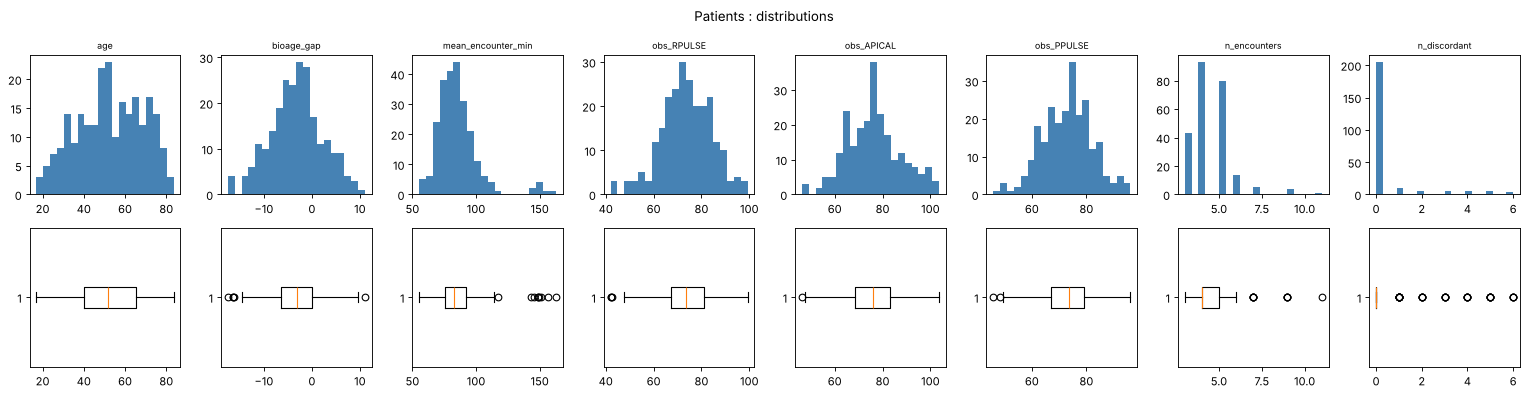

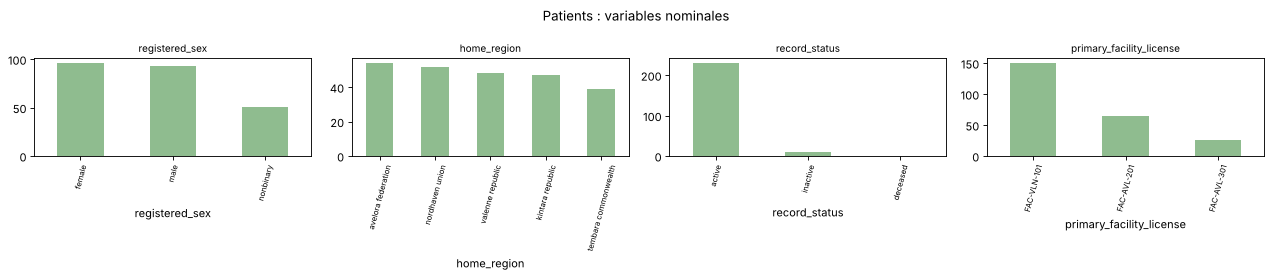

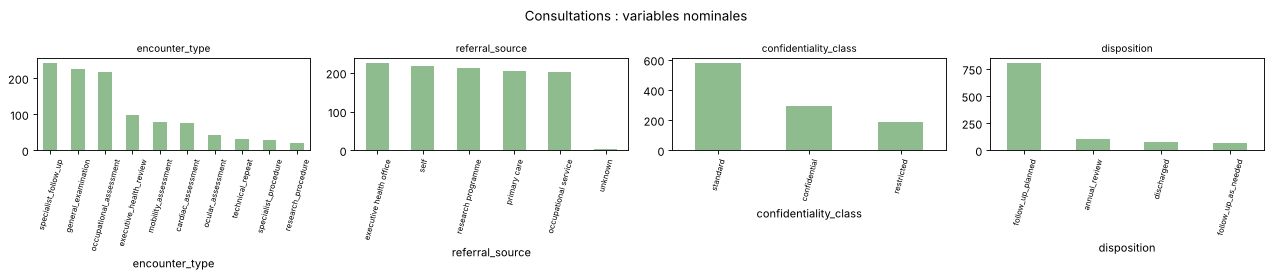

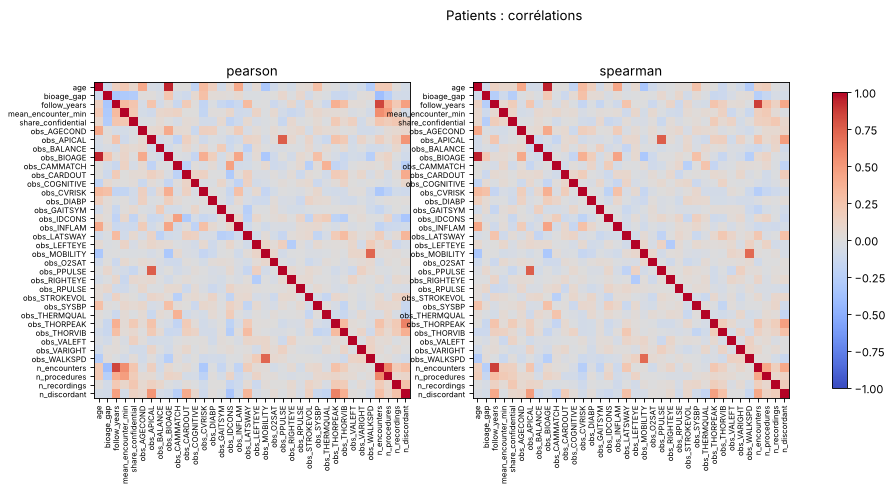

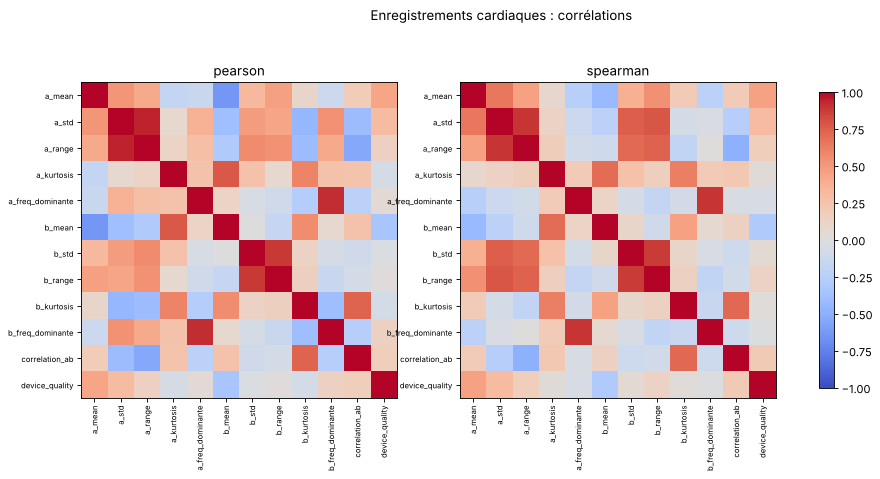

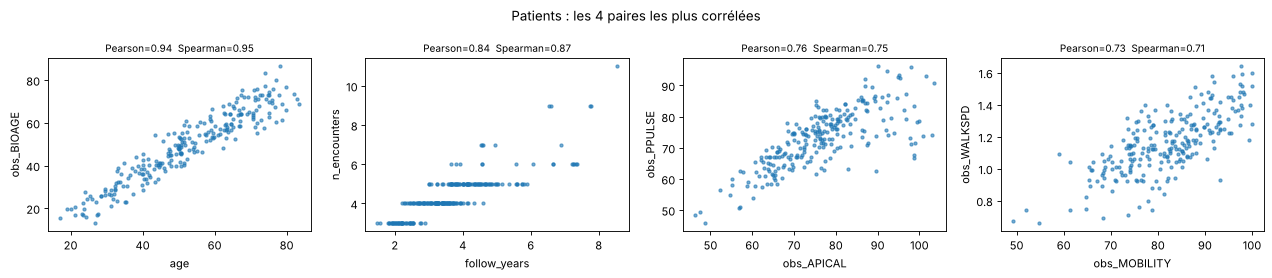

Préparation des matrices :
  variables retirées car redondantes : ['obs_BIOAGE']
  variables retirées car redondantes : []
Réduction de dimensions et clustering :
  Patients : la PCA garde 19 % de la variance avec 2 axes
  Patients : silhouette par k = {2: 0.171, 3: 0.051, 4: 0.066, 5: 0.056, 6: 0.056, 7: 0.049, 8: 0.051} -> k = 2
  Patients : DBSCAN (eps = 6.97) -> 1 groupe(s), 15 point(s) bruit


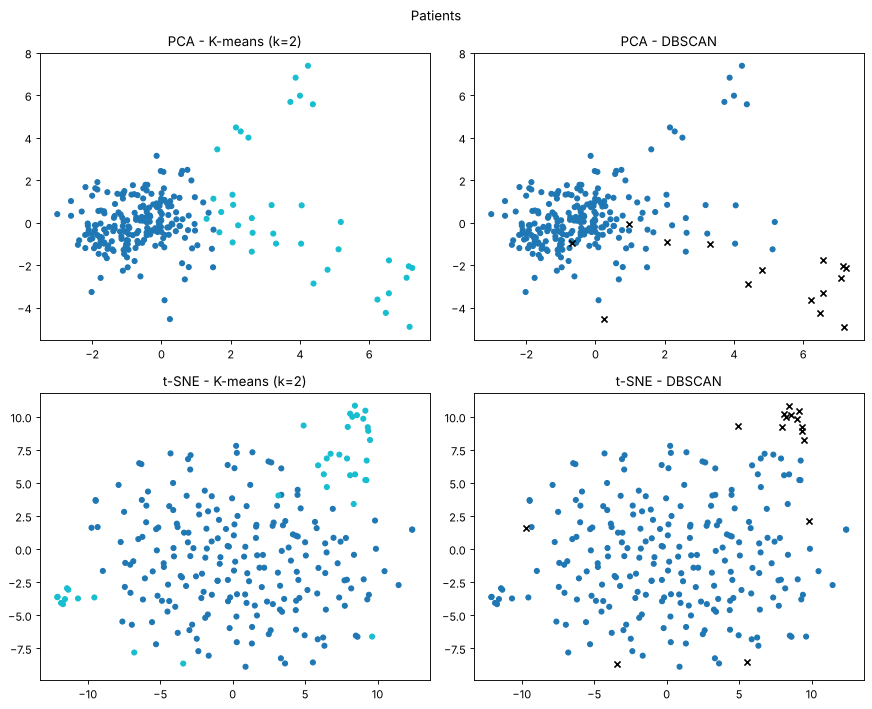

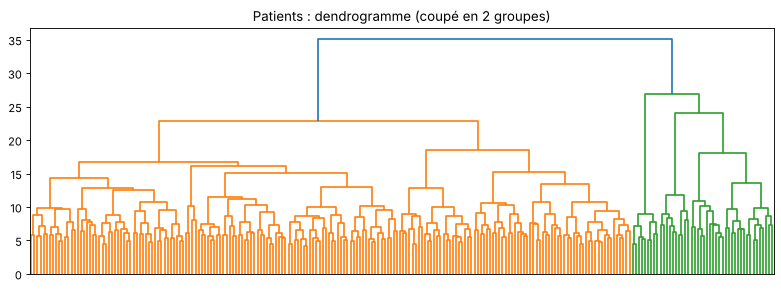

  Patients : comparaison K-means / agglomératif
cluster_agglo     1   2
cluster_kmeans         
0               192  11
1                 2  35
  Enregistrements : la PCA garde 54 % de la variance avec 2 axes
  Enregistrements : silhouette par k = {2: 0.36, 3: 0.391, 4: 0.343, 5: 0.315, 6: 0.285, 7: 0.289, 8: 0.293} -> k = 3
  Enregistrements : DBSCAN (eps = 4.47) -> 1 groupe(s), 4 point(s) bruit


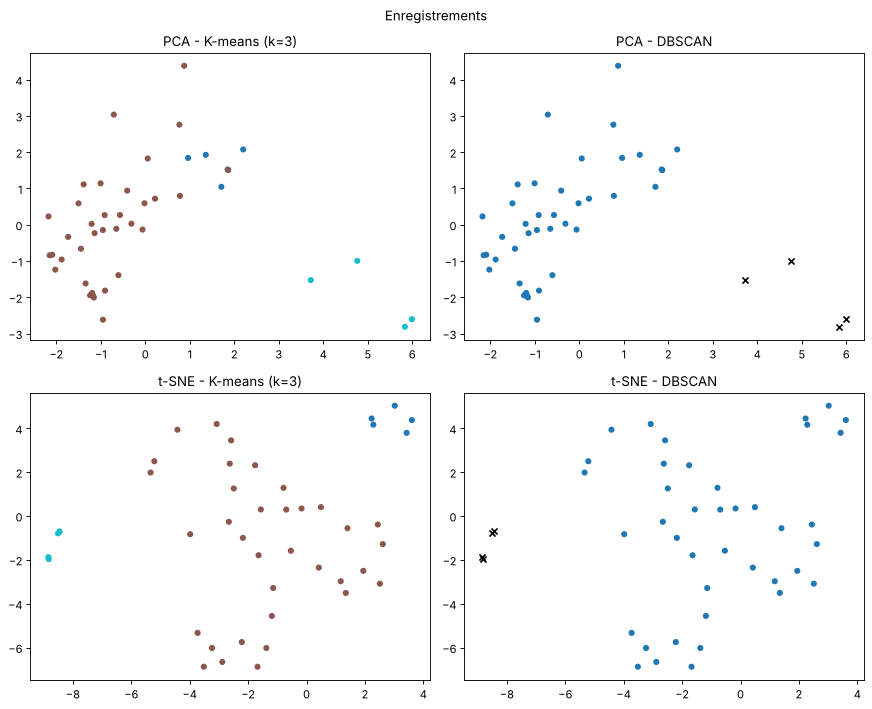

Fichiers écrits dans : /home/aleyna/MIAOU/DM/20262027-UE-DataMining-Groupe10/data/health_clean


In [11]:
res = run_pipeline()      # lit data/health/ et écrit dans data/health_clean/

## 11. Résultats

In [12]:
print("Statistiques des patients")
display(res["stats_patients"])
print("Statistiques des enregistrements cardiaques")
display(res["stats_enregistrements"])

Statistiques des patients


,mean,std,min,25%,50%,75%,max,skew,%manquants
age,52.528668,15.933917,17.004791,40.273101,51.500342,65.54757,83.509925,-0.14,0.0
bioage_gap,-3.209501,5.415931,-17.518686,-6.466812,-3.087201,-0.056964,11.040657,-0.02,0.0
follow_years,3.677652,1.269918,1.489391,2.78371,3.563313,4.237509,8.533881,1.12,0.0
mean_encounter_min,85.288571,16.593181,55.333333,75.625,82.708333,91.8125,163.0,2.06,0.0
share_confidential,0.440479,0.249246,0.0,0.25,0.4,0.6,1.0,0.16,0.0
obs_AGECOND,0.979167,0.91225,0.0,0.0,1.0,2.0,4.0,0.64,0.0
obs_APICAL,76.397083,11.325072,46.3,68.425,76.075,83.0875,103.6,0.15,0.0
obs_BALANCE,76.899167,12.39032,44.6,68.5625,77.6,85.275,100.0,-0.1,0.0
obs_BIOAGE,49.319167,16.293898,13.1,38.1125,50.75,61.8125,86.5,-0.18,0.0
obs_CAMMATCH,89.382083,9.356235,40.6,84.825,91.25,95.8,100.0,-1.73,0.0


Statistiques des enregistrements cardiaques


,mean,std,min,25%,50%,75%,max,skew,%manquants
a_mean,0.082872,0.035417,0.000709,0.070983,0.08366,0.101301,0.173345,-0.18,0.0
a_std,0.463643,0.066518,0.398551,0.420501,0.443177,0.484411,0.663705,1.95,0.0
a_range,3.178289,0.529603,2.442497,2.850347,3.065161,3.262919,4.537081,1.24,0.0
a_kurtosis,4.022184,1.07156,1.191519,3.660212,4.099289,4.486514,7.134215,-0.38,0.0
a_freq_dominante,3.223359,2.286801,0.066667,2.433333,3.291667,3.847222,11.0,1.57,0.0
b_mean,0.052153,0.044464,-0.095551,0.045311,0.061915,0.081907,0.109132,-1.44,0.0
b_std,0.4133,0.028557,0.364318,0.39381,0.413219,0.431396,0.491435,0.51,0.0
b_range,2.808431,0.340221,2.304644,2.5407,2.784114,2.983407,3.695268,0.57,0.0
b_kurtosis,3.248606,1.554479,0.108388,2.177826,3.464541,4.375974,6.537999,-0.32,0.0
b_freq_dominante,3.586111,2.452884,0.133333,2.675,3.3125,4.075,11.0,1.22,0.0


In [13]:
print("Corrélations les plus fortes (patients)")
display(plus_fortes_correlations(res["patients"], res["cols_patients"]))
print("Corrélations les plus fortes (enregistrements)")
display(plus_fortes_correlations(res["enregistrements"], res["cols_enregistrements"]))

Corrélations les plus fortes (patients)


,,spearman
age,obs_BIOAGE,0.947145
follow_years,n_encounters,0.867020
obs_APICAL,obs_PPULSE,0.753564
obs_MOBILITY,obs_WALKSPD,0.709733
obs_APICAL,n_discordant,0.476858
obs_THORPEAK,n_discordant,0.463809
obs_BIOAGE,obs_INFLAM,0.445169
age,obs_INFLAM,0.433888


Corrélations les plus fortes (enregistrements)


spearman
a_freq_dominante b_freq_dominante  0.894742
a_std            a_range           0.892882
b_std            b_range           0.880197
a_std            b_range           0.783087
                 b_std             0.750388
a_range          b_range           0.738548
b_kurtosis       correlation_ab    0.714024
a_range          b_std             0.707400

In [14]:
# Profil de chaque groupe de patients (médianes dans l'échelle d'origine) pour pouvoir les interpréter
cles = ["age", "bioage_gap", "n_encounters", "n_procedures", "n_discordant", "obs_RPULSE", "obs_APICAL", "obs_PPULSE", "obs_THORPEAK"]
p = res["patients"]
profil = p.groupby("cluster_kmeans")[cles].median().round(2)
profil.insert(0, "effectif", p.groupby("cluster_kmeans").size())
display(profil)

# Groupes d'enregistrements selon le contexte d'enregistrement
e = res["enregistrements"]
display(pd.crosstab(e["cluster_kmeans"], e["recording_context"]))
print("Enregistrements 'bruit' de DBSCAN :", list(e.index[e["cluster_dbscan"] == -1]))

,effectif,age,bioage_gap,n_encounters,n_procedures,n_discordant,obs_RPULSE,obs_APICAL,obs_PPULSE,obs_THORPEAK
cluster_kmeans,,,,,,,,,,
0,203,51.47,-2.58,4.0,1.0,0.0,74.1,75.2,74.3,22.95
1,37,51.63,-8.30,6.0,2.0,3.0,70.1,87.8,73.0,51.15


recording_context,clinical_follow_up,post_exercise,rest,stress_assessment,technical_repeat
cluster_kmeans,,,,,
0,0,3,0,2,0
1,6,4,20,3,2
2,0,0,0,0,4


Enregistrements 'bruit' de DBSCAN : ['CRD-410002', 'CRD-410017', 'CRD-410028', 'CRD-410041']


## 12. Bilan des parties 1 à 11 (cours 1 et 2)

### Ce qui a été fait
**Nettoyage**
* **Doublons** : 1 patient, 2 consultations, 2 observations, 1 procédure (lignes strictement identiques).
* **Formats inconsistants** : dates écrites de 5 façons différentes → un seul format ; valeurs comme `"84,9"` ou `"77.4 bpm"` → nombre pur.
* **Catégories non fixes** : casse et espaces harmonisés ; un seul nom par code d'observation.
* **Manquants** : modalité explicite (`unknown`, `no_material`) quand le vide a un sens ; `follow_up_date` laissé vide (dernière consultation = pas de suivi) avec une colonne 0/1 ; colonne 100 % vide supprimée.
* **Valeurs aberrantes** : aucune valeur impossible trouvée. Les mesures hors de la plage clinique (126) sont **gardées** et signalées (`hors_plage`) : un pouls à 42 bpm est un résultat médical, pas une erreur de saisie (« un outlier peut être une anomalie intéressante »).

**Organisation** : une ligne par patient (240) et par enregistrement (44) → retrait des variables redondantes → standardisation + one-hot → PCA / t-SNE → K-means / DBSCAN / agglomératif.

### Pourquoi ces choix
| Choix | Pourquoi | Limite |
|---|---|---|
| Dates `19/12/2018` lues en **jour/mois/année** | `19/12` est impossible en mois/jour ; `01/09/2019` est cohérent avec les inscriptions faites le 1er du mois | une date ambiguë isolée reste une hypothèse |
| Médiane pour résumer les mesures d'un patient | robuste aux valeurs extrêmes (cours 1) | on perd la variabilité entre consultations |
| `log1p` sur les comptages | loi de puissance | – |
| Imputation par la médiane | simple et robuste | réduit un peu la variance |
| Standardisation de tout le continu | sinon la plus grande échelle domine la distance (cours 2, slide 7) | écart assumé avec le cours pour les scores 0-100 |
| One-hot avec poids 0,5 | les catégories ne doivent pas dominer les ~25 variables continues | le 0,5 est un choix, à tester |
| Signal non re-normalisé | les colonnes sont déjà `*_normalized` | – |
| Silhouette pour choisir *k* | critère simple et objectif | valeur faible = groupes peu séparés |
| Ward pour l'agglomératif | cohérent avec la distance euclidienne et K-means | très coûteux si beaucoup de patients (ici 240, ça va) |

### Lecture des résultats
* Les tables sont cohérentes entre elles (aucune clé orpheline).
* Les barplots montrent que les régions et les sources d'adressage sont assez équilibrées. Par contre il y a moins de patients `nonbinary`, l'établissement `FAC-VLN-101` est majoritaire et presque tous les dossiers sont `active`.
* Le nuage `obs_APICAL` / `obs_PPULSE` est intéressant : la relation est linéaire pour la plupart des patients, mais un petit paquet de points est nettement **sous la diagonale** (pouls mesuré au cœur bien plus élevé qu'au poignet). C'est ce petit paquet qu'on retrouve ensuite partout.
* **Patients** : K-means isole un petit groupe (≈ 37 patients) avec plus de mesures « discordant », un pouls apical bien plus haut que le pouls périphérique et un indice thoracique élevé. La silhouette est faible (≈ 0,17) : c'est plutôt un gradient que deux blocs bien séparés, donc à interpréter avec prudence.
* Le clustering **agglomératif** retrouve presque la même chose (227 patients sur 240 classés pareil), donc le petit groupe ne dépend pas juste de l'initialisation de K-means.
* **Enregistrements** : un groupe ne contient que des `technical_repeat` (4 sur 6).
* **DBSCAN** ne trouve qu'un seul groupe dense et quelques points « bruit », qu'on regarde en détail en partie 14.
* **Corrélation n'est pas causalité** : les groupes décrivent des ressemblances, pas des causes.
* Les noms des patients ne sont pas utilisés dans l'analyse (données identifiantes).

# Cours 3 : patterns et anomalies

## 13. Repérer des patterns

L'idée du cours (slide 5) est de voir les données comme des **transactions** composées d'**items**. Chez nous :
* une **transaction = un patient** ;
* les **items** = ce qu'on trouve dans son dossier : les procédures qu'il a reçues (`proc_...`), les types de consultation (`consult_...`), s'il a été adressé par le service santé des dirigeants, et les observations anormales (pouls « discordant », suivi oculaire « atypical », test vestibulaire « abnormal »).

Apriori ne travaille qu'avec des items présents / absents, donc on a **discrétisé** quelques variables numériques (slide 11) avec un seuil simple, choisi en regardant les histogrammes de la partie 5 :
* `age_sup_70` : âge > 70 ans ;
* `bioage_inf_age_10ans` : âge biologique estimé plus de 10 ans en dessous de l'âge réel ;
* `pic_thoracique_sup_50` : indice de « pic thoracique secondaire » > 50 ;
* `camera_match_inf_75` : confiance de la reconnaissance caméra < 75.

Ces seuils sont arbitraires, on en a conscience : un autre seuil changerait un peu les supports.

In [15]:
def construire_transactions(t, patients):
    """Une transaction par patient = l'ensemble des 'items' présents dans son dossier."""
    items = {pid: set() for pid in patients.index}
    c, o, r = t["consultations"], t["observations"], t["procedures"]

    # procédures reçues et types de consultation
    for pid, code in zip(r["patient_number"], r["procedure_code"]):
        items[pid].add("proc_" + code)
    for pid, typ in zip(c["patient_number"], c["encounter_type"]):
        items[pid].add("consult_" + typ)

    # adressé au moins une fois par le service santé des dirigeants
    for pid in c.loc[c["referral_source"] == "executive health office", "patient_number"]:
        items[pid].add("adresse_executive_office")

    # observations anormales (texte)
    for pid in o.loc[o["interpretation_code"] == "discordant", "patient_number"]:
        items[pid].add("obs_pouls_discordant")
    for pid in o.loc[(o["observation_code"] == "OCULAR") & (o["text_value"] == "atypical"), "patient_number"]:
        items[pid].add("obs_oculaire_atypique")
    for pid in o.loc[(o["observation_code"] == "VESTIB") & (o["text_value"] == "abnormal"), "patient_number"]:
        items[pid].add("obs_vestibulaire_anormal")

    # variables numériques -> discrétisées avec un seuil (cours 3, slide 11)
    seuils = {
        "age_sup_70": patients["age"] > 70,
        "bioage_inf_age_10ans": patients["bioage_gap"] < -10,
        "pic_thoracique_sup_50": patients["obs_THORPEAK"] > 50,
        "camera_match_inf_75": patients["obs_CAMMATCH"] < 75,
    }
    for nom, masque in seuils.items():
        for pid in patients.index[masque]:
            items[pid].add(nom)

    return pd.Series({pid: frozenset(s) for pid, s in items.items()})


t = res["tables"]
patients = res["patients"]
transactions = construire_transactions(t, patients)
print("Nombre de transactions (patients) :", len(transactions))
print("Exemple :", sorted(transactions.iloc[0]))

Nombre de transactions (patients) : 240
Exemple : ['adresse_executive_office', 'bioage_inf_age_10ans', 'camera_match_inf_75', 'consult_cardiac_assessment', 'consult_mobility_assessment', 'consult_ocular_assessment', 'obs_oculaire_atypique', 'obs_pouls_discordant', 'pic_thoracique_sup_50', 'proc_MOB-PNL', 'proc_OCT-TRK']


### 13.1 Matrice de co-occurrences
On met la matrice en **pourcentage par ligne** (bonne pratique du cours, slide 4) : la case (ligne i, colonne j) = « parmi les patients qui ont i, combien % ont aussi j ».

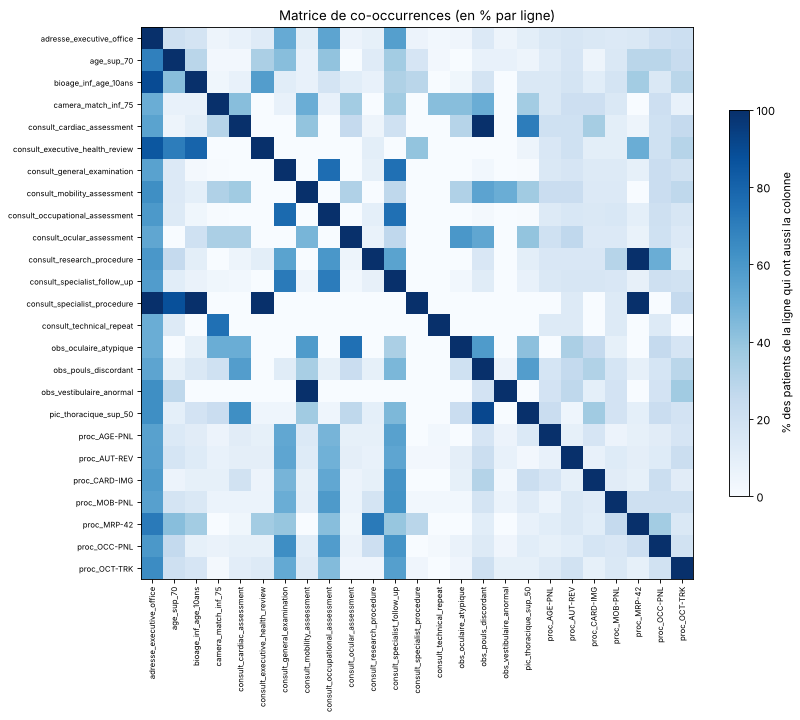

Support de chaque item (en % des patients) :


,adresse_executive_office,consult_specialist_follow_up,consult_general_examination,consult_occupational_assessment,proc_OCT-TRK,proc_OCC-PNL,age_sup_70,proc_AUT-REV,proc_AGE-PNL,proc_CARD-IMG,obs_pouls_discordant,proc_MOB-PNL,proc_MRP-42,bioage_inf_age_10ans,pic_thoracique_sup_50,consult_mobility_assessment,consult_cardiac_assessment,consult_research_procedure,consult_executive_health_review,consult_ocular_assessment,camera_match_inf_75,obs_oculaire_atypique,obs_vestibulaire_anormal,consult_technical_repeat,consult_specialist_procedure
support_%,59.2,57.9,55.0,54.2,20.0,19.6,17.5,17.1,15.0,15.0,14.6,14.2,11.7,11.7,9.2,9.2,8.3,8.3,8.3,6.2,5.8,5.0,4.6,3.3,3.3


In [16]:
def matrice_binaire(transactions):
    """Tableau patients x items avec des 0/1 (comme dans le cours, slide 5)."""
    tous = sorted(set().union(*transactions))
    return pd.DataFrame([[int(i in tr) for i in tous] for tr in transactions],
                        index=transactions.index, columns=tous)


binaire = matrice_binaire(transactions)
cooc = binaire.T @ binaire                                  # nb de patients ayant les 2 items
cooc_pct = cooc.div(np.diag(cooc), axis=0) * 100           # en % par ligne

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cooc_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(cooc_pct)))
ax.set_xticklabels(cooc_pct.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(cooc_pct)))
ax.set_yticklabels(cooc_pct.index, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7, label="% des patients de la ligne qui ont aussi la colonne")
ax.set_title("Matrice de co-occurrences (en % par ligne)")
plt.tight_layout()
plt.show()

print("Support de chaque item (en % des patients) :")
display((binaire.mean() * 100).round(1).sort_values(ascending=False).to_frame("support_%").T)

**Ce qu'on voit :**
* Les items très fréquents (`adresse_executive_office`, `consult_general_examination`, `consult_specialist_follow_up`, `consult_occupational_assessment`, plus de 50 % des patients) donnent des colonnes bleues partout, ce qui n'apprend pas grand-chose. C'est la limite de la matrice : il faut tenir compte de la fréquence de base, d'où le **lift** juste après.
* Quelques cases à 100 % sautent aux yeux : `consult_specialist_procedure` → `consult_executive_health_review` et `bioage_inf_age_10ans`, `consult_research_procedure` → `proc_MRP-42`, `obs_vestibulaire_anormal` → `consult_mobility_assessment`.
* Il y a aussi un petit bloc « pouls discordant / pic thoracique / caméra / oculaire atypique / consultation cardiaque » qui semble aller ensemble.

### 13.2 Itemsets fréquents et règles d'association (Apriori)
On a codé l'algorithme Apriori nous-mêmes en suivant le pseudo-code du cours (slide 10) : on part des items fréquents seuls, on fabrique les candidats de taille *k* à partir de ceux de taille *k − 1*, on fait le **pruning** (tous les sous-ensembles doivent être fréquents) puis on garde ceux dont le support dépasse le seuil.

* `min_support = 0,03` : un itemset doit concerner au moins ~7 patients. Avec 0,1 (24 patients), on perdrait tous les itemsets des 8 patients `mrp_recurrent`, alors que ce sont justement les petits groupes qui nous intéressent.
* Pour chaque règle X → Y on calcule la **confiance** P(Y|X), le **lift** (confiance / support de Y : > 1 veut dire que X et Y vont ensemble plus que par hasard) et le **leverage**.
* On ne garde que les règles de confiance ≥ 0,8, et on trie par lift. Y est un seul item pour que ce soit lisible.

In [17]:
def apriori(transactions, min_support):
    """Version simple de l'algorithme Apriori vu en cours (slide 10).
    Renvoie un dictionnaire {itemset: support relatif}."""
    n = len(transactions)

    def support(itemset):
        return sum(itemset <= tr for tr in transactions) / n

    # L1 : les items fréquents tout seuls
    items = sorted(set().union(*transactions))
    L = [frozenset([i]) for i in items if support(frozenset([i])) >= min_support]
    frequents = {x: support(x) for x in L}

    k = 2
    while L:
        # candidats de taille k = union de deux itemsets fréquents de taille k-1
        candidats = set()
        for a, b in combinations(L, 2):
            c = a | b
            # pruning : tous les sous-ensembles de taille k-1 doivent être fréquents
            if len(c) == k and all(frozenset(s) in frequents for s in combinations(c, k - 1)):
                candidats.add(c)
        # on ne garde que les candidats assez fréquents
        L = [c for c in candidats if support(c) >= min_support]
        frequents.update({c: support(c) for c in L})
        k += 1
    return frequents


def regles_association(frequents, min_conf=0.8, taille_max_x=2):
    """Règles X -> Y (Y = un seul item pour que ce soit lisible) avec confiance, lift et leverage."""
    regles = []
    for itemset, sup in frequents.items():
        if len(itemset) < 2 or len(itemset) - 1 > taille_max_x:
            continue
        for y in itemset:
            x = itemset - {y}
            sup_x, sup_y = frequents[x], frequents[frozenset([y])]
            conf = sup / sup_x
            regles.append({"X": " + ".join(sorted(x)), "Y": y, "support": sup,
                           "confiance": conf, "lift": conf / sup_y, "leverage": sup - sup_x * sup_y})
    regles = pd.DataFrame(regles)
    return regles[regles["confiance"] >= min_conf].sort_values(["lift", "support"], ascending=False)


# min_support = 3 % : environ 7 patients. Plus haut, on raterait les petits groupes.
frequents = apriori(transactions, min_support=0.03)
print("Nombre d'itemsets fréquents :", len(frequents))
regles = regles_association(frequents, min_conf=0.8)
print("Nombre de règles avec confiance >= 0,8 :", len(regles))
display(regles.head(15).round(3))

Nombre d'itemsets fréquents : 230
Nombre de règles avec confiance >= 0,8 : 68


,X,Y,support,confiance,lift,leverage
290,bioage_inf_age_10ans + proc_MRP-42,consult_specialist_procedure,0.033,0.8,24.000,0.032
356,consult_executive_health_review + proc_MRP-42,consult_specialist_procedure,0.033,0.8,24.000,0.032
247,age_sup_70 + bioage_inf_age_10ans,consult_executive_health_review,0.050,1.0,12.000,0.046
412,consult_occupational_assessment + proc_MRP-42,consult_research_procedure,0.050,1.0,12.000,0.046
168,consult_specialist_follow_up + proc_MRP-42,consult_research_procedure,0.046,1.0,12.000,0.042
193,consult_general_examination + proc_MRP-42,consult_research_procedure,0.046,1.0,12.000,0.042
304,proc_MRP-42 + proc_OCC-PNL,consult_research_procedure,0.042,1.0,12.000,0.038
60,consult_specialist_procedure,consult_executive_health_review,0.033,1.0,12.000,0.031
217,adresse_executive_office + consult_specialist_procedure,consult_executive_health_review,0.033,1.0,12.000,0.031
286,bioage_inf_age_10ans + consult_specialist_procedure,consult_executive_health_review,0.033,1.0,12.000,0.031


In [18]:
# Zoom sur les règles qui contiennent la procédure MRP-42 ou la discordance du pouls
masque = regles["X"].str.contains("MRP|discordant|thoracique") | regles["Y"].str.contains("MRP|discordant|thoracique")
display(regles[masque & (regles["lift"] > 2)].head(12).round(3))

,X,Y,support,confiance,lift,leverage
290,bioage_inf_age_10ans + proc_MRP-42,consult_specialist_procedure,0.033,0.8,24.000,0.032
356,consult_executive_health_review + proc_MRP-42,consult_specialist_procedure,0.033,0.8,24.000,0.032
412,consult_occupational_assessment + proc_MRP-42,consult_research_procedure,0.050,1.0,12.000,0.046
168,consult_specialist_follow_up + proc_MRP-42,consult_research_procedure,0.046,1.0,12.000,0.042
193,consult_general_examination + proc_MRP-42,consult_research_procedure,0.046,1.0,12.000,0.042
304,proc_MRP-42 + proc_OCC-PNL,consult_research_procedure,0.042,1.0,12.000,0.038
354,consult_specialist_procedure + proc_MRP-42,consult_executive_health_review,0.033,1.0,12.000,0.031
277,bioage_inf_age_10ans + proc_MRP-42,consult_executive_health_review,0.038,0.9,10.800,0.034
73,consult_research_procedure,proc_MRP-42,0.083,1.0,8.571,0.074
382,adresse_executive_office + consult_research_procedure,proc_MRP-42,0.050,1.0,8.571,0.044


**Ce qu'on en retient :**
* `consult_specialist_procedure` → `consult_executive_health_review` avec une confiance de 1 et un **lift de 12** : toutes les « procédures de spécialiste » sont faites chez des patients suivis en bilan de santé « dirigeant ».
* `bioage_inf_age_10ans + proc_MRP-42` → `consult_specialist_procedure` : lift de **24**, le plus élevé. Il relie trois choses : la procédure **MRP-42** (« Targeted metabolic resilience administration »), un âge biologique bien plus bas que l'âge réel et le bilan « dirigeant ».
* `consult_research_procedure` → `proc_MRP-42` (confiance 1, lift 8,6) : MRP-42 est aussi donnée dans un cadre de **recherche**, à d'autres patients.
* `obs_vestibulaire_anormal` → `consult_mobility_assessment` (lift ≈ 11) : logique médicalement, pas surprenant.

Donc MRP-42 semble être donnée à **deux populations différentes**. On regarde ça de plus près.

### 13.3 Deux profils de patients
Pour la suite, on donne un **profil** à chaque patient à partir de ce qu'on a trouvé jusqu'ici :
* `mrp_recurrent` : a reçu MRP-42 **au moins 2 fois** ;
* `mrp_une_fois` : a reçu MRP-42 une seule fois ;
* `phenotype_atypique` : fait partie du petit groupe K-means de la partie 7 (pouls discordant, pic thoracique...) ;
* `autre` : le reste.

(Si un patient est dans plusieurs cas, on garde le premier de la liste : récurrent > atypique > une fois.)

In [19]:
# On construit deux groupes à partir de ce qu'on vient de voir.
mrp = t["procedures"][t["procedures"]["procedure_code"] == "MRP-42"]
n_mrp = mrp.groupby("patient_number").size().reindex(patients.index, fill_value=0)
petit_cluster = patients["cluster_kmeans"].value_counts().idxmin()   # le petit groupe K-means

patients["profil"] = "autre"
patients.loc[n_mrp == 1, "profil"] = "mrp_une_fois"
patients.loc[patients["cluster_kmeans"] == petit_cluster, "profil"] = "phenotype_atypique"
patients.loc[n_mrp >= 2, "profil"] = "mrp_recurrent"
print(patients["profil"].value_counts())

# Qui sont les patients qui reçoivent MRP-42 plusieurs fois ?
infos = t["patients"].set_index("patient_number")[["occupation_text", "home_region"]]
recurrents = patients[patients["profil"] == "mrp_recurrent"]
tableau = infos.loc[recurrents.index].assign(age=recurrents["age"].round(0),
                                             bioage_gap=recurrents["bioage_gap"].round(1),
                                             nb_mrp42=n_mrp[recurrents.index])
display(tableau.sort_values("nb_mrp42", ascending=False))

# Comment MRP-42 est autorisé selon le groupe
display(pd.crosstab(mrp["patient_number"].map(patients["profil"]), mrp["authorization_class"]))

# Groupe de comparaison : patients suivis en "executive_health_review" mais qui n'ont jamais eu MRP-42
c = t["consultations"]
a_une_executive_review = (c["encounter_type"] == "executive_health_review").groupby(c["patient_number"]).any()
a_une_executive_review = a_une_executive_review.reindex(patients.index, fill_value=False)
groupe_age = pd.Series("autres patients", index=patients.index)
groupe_age[a_une_executive_review & (n_mrp == 0)] = "executive_review sans MRP-42"
groupe_age[n_mrp >= 2] = "MRP-42 récurrent"
display(patients.groupby(groupe_age)[["age", "bioage_gap"]].median().round(1)
        .assign(nb_patients=groupe_age.value_counts()))

profil
autre                 188
phenotype_atypique     29
mrp_une_fois           15
mrp_recurrent           8
Name: count, dtype: int64


,occupation_text,home_region,age,bioage_gap,nb_mrp42
patient_number,,,,,
PAT-31221,head of government of kintara republic,kintara republic,77.0,-16.5,5
PAT-31044,senior minister of the avelora federation,avelora federation,72.0,-16.4,4
PAT-31174,regional governor in the tembara commonwealth,tembara commonwealth,80.0,-13.7,4
PAT-31119,chief executive of solvane energy group,valenne republic,74.0,-16.2,4
PAT-31074,executive chair of nivren maritime logistics,nordhaven union,79.0,-17.5,4
PAT-31183,executive director of ardena capital union,valenne republic,62.0,-14.0,3
PAT-31142,chair of belen agro-industries,kintara republic,71.0,-12.9,3
PAT-31099,retired political intermediary and former council president,avelora federation,83.0,-12.0,3


authorization_class,research_restricted,restricted_specialist
patient_number,,
mrp_recurrent,0,30
mrp_une_fois,15,0
phenotype_atypique,5,0


,age,bioage_gap,nb_patients
MRP-42 récurrent,75.4,-15.1,8
autres patients,50.8,-2.6,222
executive_review sans MRP-42,72.3,-11.0,10


**Ce qu'on observe :**
* Les **8 patients** qui reçoivent MRP-42 plusieurs fois sont tous des personnes de pouvoir : chef de gouvernement de Kintara, ministre de la fédération d'Avelora, gouverneur régional, plusieurs présidents / directeurs de grands groupes (énergie, logistique maritime, finance, agro-industrie) et un ancien président de conseil. Ils sont âgés (62 à 83 ans) et ont **un âge biologique 12 à 17 ans plus bas** que leur âge réel.
* Chez eux, MRP-42 est toujours en `restricted_specialist`. Chez les autres patients (les 20 qui l'ont eu une fois), c'est toujours `research_restricted` : même produit, deux circuits différents.
* Le groupe de comparaison est important : les patients suivis en `executive_health_review` **sans** MRP-42 ont aussi un âge biologique plus bas (−11 ans en médiane, contre −2,6 pour les autres). Les patients MRP-42 récurrents sont encore plus bas (−15). Il y a donc un gradient, mais **on ne peut pas dire que MRP-42 cause le rajeunissement** : les personnes suivies par ce service sont aussi plus aisées et mieux suivies (biais de sélection), et on n'a que 8 patients.

## 14. Détecter des anomalies

### 14.1 Détection univariée
On applique les trois méthodes du cours (slide 14) à quelques variables :
* **IQR** : aberrant si < Q1 − 1,5×IQR ou > Q3 + 1,5×IQR ;
* **z-score** : aberrant si |z| > 3 ;
* **z-score modifié** : (x − médiane) / écart absolu médian, avec la formule du cours. On a pris le même seuil de 3.

On ajoute une variable calculée : `ecart_pouls` = pouls apical (au cœur) − pouls périphérique (au poignet). Normalement les deux devraient être à peu près égaux.

La colonne `profils_IQR` dit à quels profils appartiennent les patients signalés par l'IQR.

,iqr,zscore,zscore_modifie,profils_IQR
ecart_pouls,14,7,23,{'phenotype_atypique': 14}
bioage_gap,5,0,20,"{'mrp_recurrent': 4, 'mrp_une_fois': 1}"
obs_THORPEAK,3,1,11,{'phenotype_atypique': 3}
obs_CAMMATCH,9,6,14,"{'autre': 5, 'phenotype_atypique': 4}"
obs_IDCONS,12,5,16,"{'phenotype_atypique': 8, 'autre': 4}"
obs_LATSWAY,15,2,32,"{'autre': 8, 'phenotype_atypique': 7}"


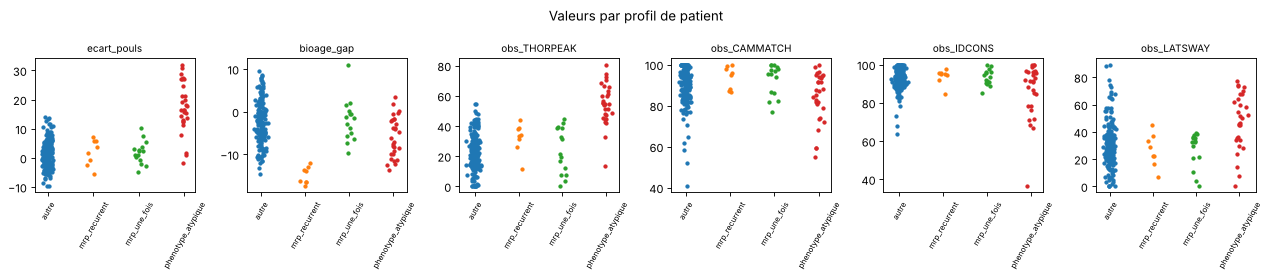

In [20]:
def anomalies_univariees(serie):
    """Nombre de valeurs aberrantes selon les 3 méthodes du cours (slide 14)."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    hors_iqr = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    z = (serie - serie.mean()) / serie.std()
    eam = (serie - serie.median()).abs().median()        # écart absolu médian
    z_mod = (serie - serie.median()) / eam
    return pd.DataFrame({"iqr": hors_iqr, "zscore": z.abs() > 3, "zscore_modifie": z_mod.abs() > 3})


# nouvelle variable : écart entre le pouls apical (au coeur) et le pouls périphérique (au poignet)
patients["ecart_pouls"] = patients["obs_APICAL"] - patients["obs_PPULSE"]

variables = ["ecart_pouls", "bioage_gap", "obs_THORPEAK", "obs_CAMMATCH", "obs_IDCONS", "obs_LATSWAY"]
resume = {}
for v in variables:
    a = anomalies_univariees(patients[v])
    resume[v] = a.sum()
    # parmi les patients signalés par l'IQR, quelle part appartient à chaque profil ?
    resume[v]["profils_IQR"] = dict(patients.loc[a["iqr"], "profil"].value_counts())
display(pd.DataFrame(resume).T)

fig, axes = plt.subplots(1, len(variables), figsize=(16, 3.5))
for ax, v in zip(axes, variables):
    for i, (nom, g) in enumerate(patients.groupby("profil")):
        ax.scatter(np.random.normal(i, 0.06, len(g)), g[v], s=8, label=nom)
    ax.set_xticks(range(patients["profil"].nunique()))
    ax.set_xticklabels(sorted(patients["profil"].unique()), rotation=60, fontsize=7)
    ax.set_title(v, fontsize=9)
plt.suptitle("Valeurs par profil de patient")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**
* Le z-score repère moins de valeurs que l'IQR : comme il utilise la moyenne et l'écart-type, les valeurs extrêmes « gonflent » l'écart-type et se cachent elles-mêmes. Le z-score modifié, lui, en repère plus que les deux autres (avec la formule du cours sans facteur correctif, le seuil de 3 est plus sévère qu'il n'en a l'air).
* `ecart_pouls` : les **14** patients signalés par l'IQR sont **tous** du profil `phenotype_atypique`. C'est la variable la plus nette.
* `bioage_gap` : les valeurs extrêmes sont 4 patients `mrp_recurrent` et 1 `mrp_une_fois`.
* `obs_IDCONS` (cohérence d'identité) et `obs_CAMMATCH` (reconnaissance caméra) : les valeurs basses sont surtout chez les atypiques, mais aussi chez quelques « autres ».
* Une valeur aberrante n'est pas forcément une **anomalie** (slide 14). Ici c'est le fait que plusieurs variables soient anormales **chez les mêmes patients** qui devient intéressant, d'où la détection multivariée.

### 14.2 Détection multivariée
Sur la matrice standardisée de la partie 6 (toutes les variables d'un coup), on compare trois méthodes :
* **DBSCAN** : les points « bruit » (le cours dit de préférer DBSCAN à K-means pour ça, slide 15) ;
* **Isolation Forest** : les patients isolés le plus vite par des coupures aléatoires ;
* **LOF** (Local Outlier Factor, slide 17) : LOF > 1 = densité plus faible que ses voisins. On a pris 20 voisins.

Comme Isolation Forest et LOF donnent un score et pas une décision, on prend les **15 patients les plus suspects** de chaque méthode (environ le même nombre que les points bruit de DBSCAN).

,DBSCAN (bruit),Isolation Forest (top 15),LOF (top 15),tous les patients
profil,,,,
autre,3,1,5,188
mrp_recurrent,0,3,4,8
mrp_une_fois,0,0,0,15
phenotype_atypique,12,11,6,29


Patients signalés par les 3 méthodes : ['PAT-31020', 'PAT-31037', 'PAT-31181', 'PAT-31186', 'PAT-31233']


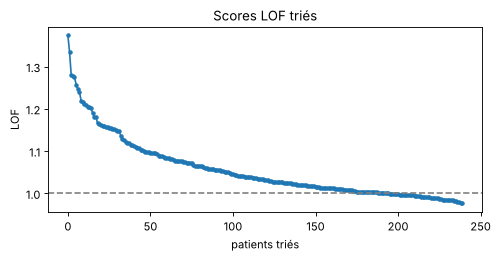

In [21]:
X_p = res["X_patients"]

# 1) DBSCAN : les points "bruit" (déjà calculés en partie 7)
bruit_dbscan = patients["cluster_dbscan"] == -1
# 2) Isolation Forest : plus le score est haut, plus le patient est isolé vite
score_iso = pd.Series(-IsolationForest(random_state=SEED).fit(X_p).score_samples(X_p), index=X_p.index)
# 3) LOF : LOF > 1 = densité plus faible que ses voisins
lof = LocalOutlierFactor(n_neighbors=20)
lof.fit_predict(X_p)
score_lof = pd.Series(-lof.negative_outlier_factor_, index=X_p.index)

# On compare les 15 patients les plus suspects selon chaque méthode
top = 15
comparaison = pd.DataFrame({
    "DBSCAN (bruit)": patients.loc[bruit_dbscan, "profil"].value_counts(),
    "Isolation Forest (top 15)": patients.loc[score_iso.nlargest(top).index, "profil"].value_counts(),
    "LOF (top 15)": patients.loc[score_lof.nlargest(top).index, "profil"].value_counts(),
    "tous les patients": patients["profil"].value_counts(),
}).fillna(0).astype(int)
display(comparaison)

# patients retrouvés par les 3 méthodes en même temps
communs = set(patients.index[bruit_dbscan]) & set(score_iso.nlargest(top).index) & set(score_lof.nlargest(top).index)
print("Patients signalés par les 3 méthodes :", sorted(communs))

# bonne pratique du cours : trier les LOF pour voir où ça "décroche"
plt.figure(figsize=(7, 3))
plt.plot(score_lof.sort_values(ascending=False).values, marker=".")
plt.axhline(1, color="grey", linestyle="--")
plt.xlabel("patients triés")
plt.ylabel("LOF")
plt.title("Scores LOF triés")
plt.show()

**Ce qu'on observe :**
* Les trois méthodes pointent surtout vers le profil `phenotype_atypique` (12/15 pour DBSCAN, 11/15 pour Isolation Forest), alors qu'il ne représente que 12 % des patients.
* LOF est plus mélangé (6 atypiques, 4 `mrp_recurrent`, 5 autres). C'est logique : LOF compare un point à ses **voisins proches**. Or les atypiques se ressemblent entre eux et forment un petit paquet assez dense, donc localement ils ne paraissent pas si anormaux.
* Les `mrp_recurrent` ressortent avec Isolation Forest et LOF (âge élevé, beaucoup de consultations, âge biologique bas).
* 5 patients sont signalés par les trois méthodes en même temps : ce sont ceux qu'on regarderait en premier « à la main ».
* Sur la courbe des LOF triés, une dizaine de patients sont au-dessus de 1,2, puis la courbe descend doucement vers 1 : pas de « cassure » nette, donc pas de seuil évident.

# Cours 4 : graphes et processus

## 15. Graphe des items

On reprend les items de la partie 13 et on construit un graphe non orienté :
* **nœud** = un item ;
* **lien** entre deux items s'ils apparaissent ensemble chez au moins 5 patients **et** avec un lift > 1,5 (sinon tout est relié à tout à cause des items très fréquents) ;
* **poids** du lien = le lift.

On calcule ensuite les mesures vues en cours : taille N, nombre de liens L, densité, degré, **betweenness** (le nœud sert de « pont »), **closeness** (le nœud est proche des autres) et **coefficient de clustering**. Puis on cherche des communautés avec **Louvain** (slide 17), qui maximise la modularité Q.

In [22]:
# Graphe : noeud = item, lien = les deux items apparaissent ensemble plus souvent que par hasard
n = len(binaire)
support_item = binaire.mean()
G = nx.Graph()
for a, b in combinations(binaire.columns, 2):
    nb = cooc.loc[a, b]
    lift = (nb / n) / (support_item[a] * support_item[b])
    if nb >= 5 and lift > 1.5:          # au moins 5 patients et lift > 1,5
        G.add_edge(a, b, weight=lift)

print(f"N = {G.number_of_nodes()} noeuds, L = {G.number_of_edges()} liens, densité d = {nx.density(G):.2f}")

mesures = pd.DataFrame({
    "degre": dict(G.degree()),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "clustering": nx.clustering(G),
}).round(3)
display(mesures.sort_values("betweenness", ascending=False).head(10))

N = 21 noeuds, L = 46 liens, densité d = 0.22


,degre,betweenness,closeness,clustering
proc_MRP-42,7,0.082,0.356,0.381
consult_mobility_assessment,8,0.071,0.432,0.571
obs_pouls_discordant,8,0.063,0.432,0.607
camera_match_inf_75,7,0.053,0.403,0.714
pic_thoracique_sup_50,8,0.034,0.432,0.643
bioage_inf_age_10ans,5,0.016,0.291,0.700
consult_specialist_procedure,5,0.016,0.291,0.700
consult_cardiac_assessment,7,0.011,0.403,0.810
consult_research_procedure,3,0.003,0.229,0.667
consult_executive_health_review,4,0.000,0.267,1.000


Louvain : 2 communautés, modularité Q = 0.45
  communauté 0 : ['adresse_executive_office', 'age_sup_70', 'bioage_inf_age_10ans', 'consult_executive_health_review', 'consult_research_procedure', 'consult_specialist_procedure', 'proc_MOB-PNL', 'proc_MRP-42', 'proc_OCC-PNL']
  communauté 1 : ['camera_match_inf_75', 'consult_cardiac_assessment', 'consult_mobility_assessment', 'consult_ocular_assessment', 'consult_technical_repeat', 'obs_oculaire_atypique', 'obs_pouls_discordant', 'obs_vestibulaire_anormal', 'pic_thoracique_sup_50', 'proc_AGE-PNL', 'proc_AUT-REV', 'proc_CARD-IMG']


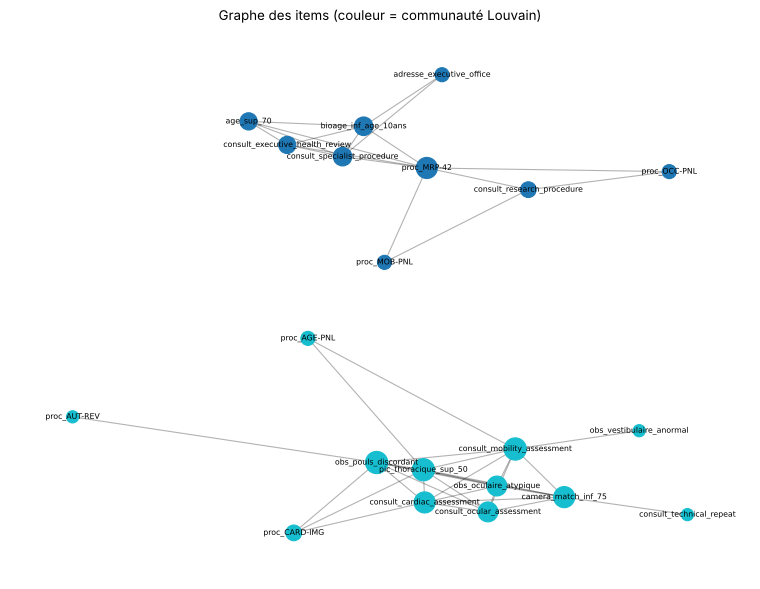

In [23]:
communautes = nx.community.louvain_communities(G, weight="weight", seed=SEED)
print(f"Louvain : {len(communautes)} communautés, modularité Q = {nx.community.modularity(G, communautes, weight='weight'):.2f}")
for i, com in enumerate(communautes):
    print(f"  communauté {i} : {sorted(com)}")

couleur = {noeud: i for i, com in enumerate(communautes) for noeud in com}
pos = nx.spring_layout(G, weight="weight", seed=SEED, k=0.9)
plt.figure(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, alpha=0.3)
nx.draw_networkx_nodes(G, pos, node_color=[couleur[x] for x in G.nodes], cmap="tab10",
                       node_size=[80 + 40 * G.degree(x) for x in G.nodes])
nx.draw_networkx_labels(G, pos, font_size=7)
plt.title("Graphe des items (couleur = communauté Louvain)")
plt.axis("off")
plt.show()

**Ce qu'on observe :**
* Le graphe est peu dense (d ≈ 0,22) et Louvain trouve **2 communautés bien séparées** (modularité Q ≈ 0,45, ce qui est assez élevé) :
  * une communauté « **dirigeants** » : `adresse_executive_office`, `consult_executive_health_review`, `consult_specialist_procedure`, `proc_MRP-42`, `bioage_inf_age_10ans`, `age_sup_70`, `consult_research_procedure` ;
  * une communauté « **phénotype atypique** » : `obs_pouls_discordant`, `pic_thoracique_sup_50`, `camera_match_inf_75`, `obs_oculaire_atypique`, `obs_vestibulaire_anormal`, consultations cardiaques, oculaires, de mobilité, `consult_technical_repeat`.
* `proc_MRP-42` a la plus forte **betweenness** : c'est le nœud qui fait le lien entre le circuit « dirigeants » et le circuit « recherche ».
* Dans la communauté « atypique », les nœuds principaux ont un fort coefficient de clustering (entre 0,57 et 0,81) : ces signes apparaissent **ensemble**, chez les mêmes patients. Pris un par un ils pourraient avoir des causes banales, mais pas tous en même temps.
* On retrouve la même séparation que le clustering de la partie 7, mais avec une méthode complètement différente, ce qui nous rassure.

## 16. Process mining sur les consultations

Un **processus** = une suite d'activités. Ici on construit un *event log* :
* **cas** = un patient ;
* **activité** = le type de consultation (`encounter_type`) ;
* **ordre** = la date de début de la consultation.

On ajoute deux nœuds spéciaux `DEBUT` et `FIN` (slide 21). On représente le processus comme un **graphe orienté pondéré** : un lien a → b veut dire « la consultation a est directement suivie par la consultation b », son poids est le nombre de fois où ça arrive.

Pour que le graphe reste lisible (sinon c'est le « spaghetti » du slide 22), on ne garde que les liens vus au moins 15 fois pour les patients « autre » (188 patients) et 3 fois pour les deux petits groupes. On fait un graphe par profil pour comparer.

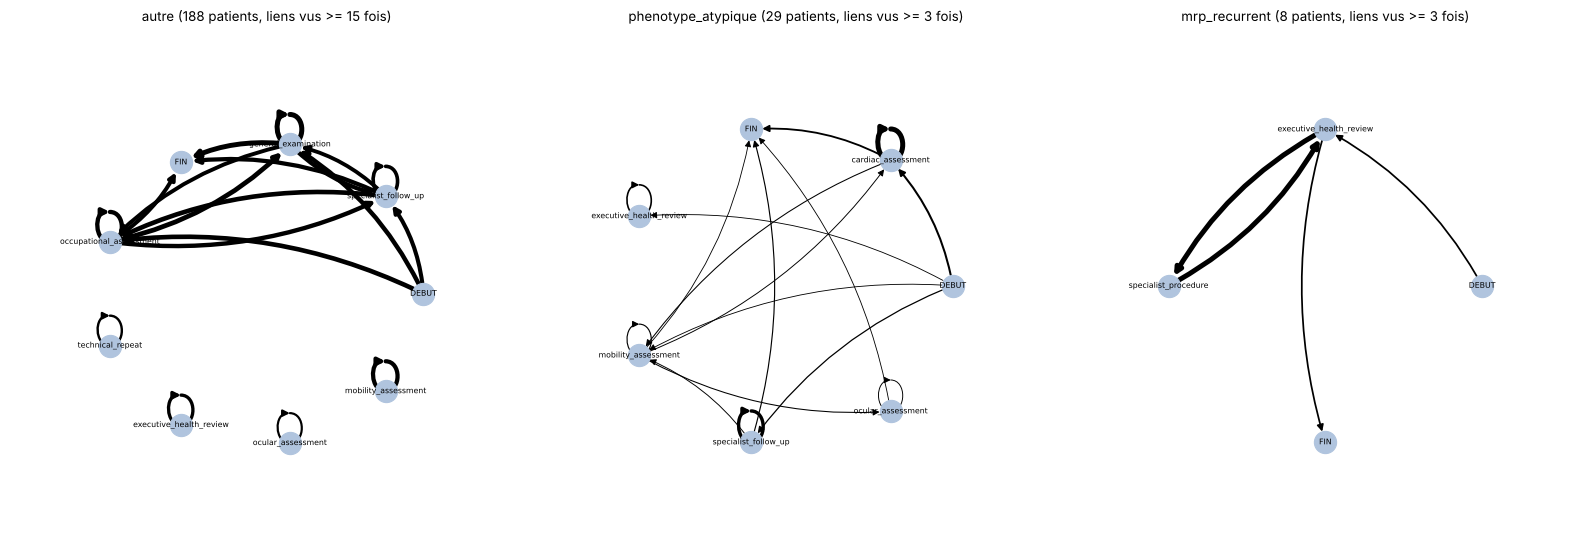

In [24]:
# Event log : cas = patient, activité = type de consultation, ordre = date de début
log = t["consultations"].sort_values(["patient_number", "encounter_start"])
traces = log.groupby("patient_number")["encounter_type"].apply(lambda s: ["DEBUT"] + list(s) + ["FIN"])
profil_trace = traces.index.map(patients["profil"])


def suivis_directs(traces):
    """Compte combien de fois l'activité a est directement suivie par b (noté a > b)."""
    compte = Counter()
    for tr in traces:
        for a, b in zip(tr[:-1], tr[1:]):
            compte[(a, b)] += 1
    return compte


def graphe_processus(traces, min_occ):
    """Processus = graphe orienté pondéré (cours 4, slide 21). On garde les liens vus au moins min_occ fois."""
    G = nx.DiGraph()
    for (a, b), nb in suivis_directs(traces).items():
        if nb >= min_occ:
            G.add_edge(a, b, weight=nb)
    return G


def dessiner_processus(G, ax, titre):
    pos = nx.circular_layout(G)
    poids = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="lightsteelblue", node_size=400)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    nx.draw_networkx_edges(G, pos, ax=ax, width=[0.5 + 4 * poids[e] / max(poids.values()) for e in G.edges],
                           arrows=True, arrowsize=12, connectionstyle="arc3,rad=0.15", node_size=400)
    ax.set_title(titre)
    ax.margins(0.25)
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, prof, min_occ in zip(axes, ["autre", "phenotype_atypique", "mrp_recurrent"], [15, 3, 3]):
    Gp = graphe_processus(traces[profil_trace == prof], min_occ)
    dessiner_processus(Gp, ax, f"{prof} ({(profil_trace == prof).sum()} patients, liens vus >= {min_occ} fois)")
plt.tight_layout()
plt.show()

Ensuite on applique le **Heuristic Miner** (slide 23) : pour chaque couple on calcule
a ⇒ b = (|a>b| − |b>a|) / (|a>b| + |b>a| + 1), et on ne garde que les liens avec une dépendance ≥ 0,6 (et vus au moins 10 fois).
Pour une boucle sur la même activité (a → a), la formule ne marche pas (ça ferait 0), donc on a pris |a>a| / (|a>a| + 1).

In [25]:
def dependances(traces):
    """Degré de dépendance du Heuristic Miner (cours 4, slide 23) pour chaque couple (a, b)."""
    ab = suivis_directs(traces)
    lignes = []
    for (a, b), nb in ab.items():
        if a == b:                       # boucle sur la même activité
            dep = nb / (nb + 1)
        else:
            dep = (nb - ab[(b, a)]) / (nb + ab[(b, a)] + 1)
        lignes.append({"a": a, "b": b, "a>b": nb, "b>a": ab[(b, a)], "dependance": round(dep, 2)})
    return pd.DataFrame(lignes).sort_values("a>b", ascending=False).reset_index(drop=True)


# Heuristic Miner sur tout le log avec un seuil lambda = 0,6
dep_tous = dependances(traces)
garde = dep_tous[(dep_tous["dependance"] >= 0.6) & (dep_tous["a>b"] >= 10)]
print(f"Suivis directs : {len(dep_tous)} liens différents -> après Heuristic Miner : {len(garde)} liens")
display(garde)

print("Dépendances calculées seulement sur les 8 patients mrp_recurrent :")
display(dependances(traces[profil_trace == "mrp_recurrent"]))

Suivis directs : 55 liens différents -> après Heuristic Miner : 22 liens


,a,b,a>b,b>a,dependance
0,specialist_follow_up,specialist_follow_up,72,72,0.99
1,general_examination,general_examination,63,63,0.98
2,DEBUT,occupational_assessment,60,0,0.98
4,general_examination,FIN,58,0,0.98
5,specialist_follow_up,FIN,58,0,0.98
6,DEBUT,specialist_follow_up,57,0,0.98
8,mobility_assessment,mobility_assessment,54,54,0.98
9,occupational_assessment,occupational_assessment,54,54,0.98
10,DEBUT,general_examination,54,0,0.98
11,cardiac_assessment,cardiac_assessment,53,53,0.98


Dépendances calculées seulement sur les 8 patients mrp_recurrent :


,a,b,a>b,b>a,dependance
0,executive_health_review,specialist_procedure,30,30,0.00
1,specialist_procedure,executive_health_review,30,30,0.00
2,DEBUT,executive_health_review,8,0,0.89
3,executive_health_review,FIN,8,0,0.89


In [26]:
# Les "variantes" les plus fréquentes du processus (suite exacte des consultations) par profil
for prof in ["autre", "phenotype_atypique", "mrp_recurrent"]:
    variantes = traces[profil_trace == prof].apply(lambda tr: " > ".join(tr[1:-1])).value_counts()
    print(f"--- {prof} : {len(variantes)} variantes différentes")
    for v, nb in variantes.head(3).items():
        print(f"   {nb} patient(s) : {v}")

--- autre : 108 variantes différentes
   12 patient(s) : mobility_assessment > mobility_assessment > mobility_assessment > mobility_assessment > mobility_assessment
   9 patient(s) : executive_health_review > executive_health_review > executive_health_review > executive_health_review > executive_health_review
   8 patient(s) : technical_repeat > technical_repeat > technical_repeat > technical_repeat
--- phenotype_atypique : 19 variantes différentes
   9 patient(s) : cardiac_assessment > cardiac_assessment > cardiac_assessment > cardiac_assessment > cardiac_assessment
   3 patient(s) : specialist_follow_up > specialist_follow_up > specialist_follow_up > specialist_follow_up > specialist_follow_up > specialist_follow_up
   1 patient(s) : cardiac_assessment > cardiac_assessment > cardiac_assessment > research_procedure > cardiac_assessment > cardiac_assessment
--- mrp_recurrent : 3 variantes différentes
   4 patient(s) : executive_health_review > specialist_procedure > executive_health_re

**Ce qu'on observe :**
* Le Heuristic Miner simplifie bien le graphe global (55 liens → 22). Il montre surtout que les patients restent dans **un seul type de suivi** : beaucoup de boucles (a → a) et peu de passages d'un type de consultation à un autre.
* Les **patients atypiques** suivent un parcours centré sur le **cœur** : la variante la plus fréquente est 5 `cardiac_assessment` d'affilée (9 patients sur 29). Chez un patient, une `research_procedure` apparaît au milieu d'une série de suivis cardiaques.
* Les **8 patients `mrp_recurrent`** ont tous **le même processus**, très régulier : `executive_health_review` → `specialist_procedure` → `executive_health_review` → ... (3 variantes qui ne diffèrent que par le nombre de répétitions). Aucun autre patient n'a ce parcours.
* **Limite du Heuristic Miner** qu'on a découverte : pour ces 8 patients, executive → specialist et specialist → executive arrivent chacun 30 fois, donc la dépendance vaut **0** et le lien est supprimé. L'algorithme efface justement le motif le plus intéressant (une alternance). C'est pour ça qu'on a dessiné le graphe des suivis directs plutôt que le résultat brut du Heuristic Miner.
* Dans le profil « autre », 9 patients n'ont que des `executive_health_review` sans procédure : ce sont les patients du groupe de comparaison de la partie 13.3.

# Cours 5 : données spatiales et temporelles

## 17. Données spatiales

Dans `health/` il n'y a **pas de coordonnées** (pas de latitude / longitude). La seule information de lieu est indirecte (slide 2) :
* la **région** de résidence du patient (5 pays / régions) ;
* l'**établissement** où ont lieu les consultations et les procédures (3 établissements).

Avec 5 régions et sans savoir lesquelles sont voisines, on ne peut pas construire de matrice de voisinage W, donc pas d'indice de Moran ni de LISA. On se limite à regarder la **répartition des profils par lieu**.

In [27]:
# Pas de coordonnées : le seul "lieu" est la région du patient et l'établissement de soin.
print("Répartition des profils par région (en % de chaque profil) :")
display((pd.crosstab(patients["profil"], patients["home_region"], normalize="index") * 100).round(0))

c = t["consultations"]
print("Établissement des consultations (en % des consultations de chaque profil) :")
display((pd.crosstab(c["patient_number"].map(patients["profil"]), c["facility_license_number"], normalize="index") * 100).round(0))

print("Qui réalise MRP-42 et où ?")
display(pd.crosstab([mrp["patient_number"].map(patients["profil"]), mrp["performing_facility_license"]],
                    mrp["performing_license_number"]))

Répartition des profils par région (en % de chaque profil) :


home_region,avelora federation,kintara republic,nordhaven union,tembara commonwealth,valenne republic
profil,,,,,
autre,23.0,21.0,22.0,15.0,19.0
mrp_recurrent,25.0,25.0,12.0,12.0,25.0
mrp_une_fois,20.0,27.0,27.0,13.0,13.0
phenotype_atypique,21.0,7.0,17.0,24.0,31.0


Établissement des consultations (en % des consultations de chaque profil) :


facility_license_number,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101
patient_number,,,
autre,23.0,12.0,65.0
mrp_recurrent,47.0,0.0,53.0
mrp_une_fois,36.0,0.0,64.0
phenotype_atypique,37.0,15.0,48.0


Qui réalise MRP-42 et où ?


performing_license_number                       LIC-VLN-MED-1001  LIC-VLN-MED-1002  LIC-VLN-MED-1003  LIC-VLN-MED-1004  LIC-VLN-MED-1006  LIC-VLN-RES-1016  LIC-VLN-RES-1044
patient_number     performing_facility_license                                                                                                                              
mrp_recurrent      FAC-AVL-201                                 0                14                 0                 0                 0                 0                 0
                   FAC-VLN-101                                 0                16                 0                 0                 0                 0                 0
mrp_une_fois       FAC-AVL-201                                 0                 1                 0                 0                 3                 1                 0
                   FAC-VLN-101                                 1                 3                 1                 1                 1                 2                 1
phenotype_atypique FAC-AVL-201                                 0                 0                 0                 0                 0                 0                 1
                   FAC-AVL-301                                 0                 0                 0                 1                 0                 0                 0
                   FAC-VLN-101                                 0                 2                 0                 1                 0                 0                 0

**Ce qu'on observe :**
* Par **région**, les patients atypiques sont un peu plus nombreux en Valenne (31 %) et en Tembara (24 %) et presque absents de Kintara (7 %). Mais avec 29 patients, quelques personnes de plus ou de moins changent tout, donc on ne conclut pas à un effet géographique.
* Les 8 dirigeants viennent de **toutes les régions** : ce n'est pas un phénomène local, c'est plutôt lié à leur fonction.
* Par **établissement**, la différence est plus nette : les `mrp_recurrent` ne vont **jamais** à `FAC-AVL-301`, et presque la moitié de leurs consultations ont lieu à `FAC-AVL-201`.
* Surtout, les **30 administrations « dirigeants » de MRP-42 ont toutes été faites par le même praticien, `LIC-VLN-MED-1002`**, dans deux établissements seulement. Les administrations « recherche » sont, elles, réparties entre 7 praticiens différents. Ça ressemble à un circuit fermé autour d'une seule personne.

## 18. Données temporelles

On a trois types de données temporelles :
1. le **nombre de consultations par mois** (une série classique) ;
2. les **dates d'administration de MRP-42** (est-ce qu'il y a une période ?) ;
3. les **signaux cardiaques** (de vraies time series, échantillonnées à 100 ou 125 Hz).

### 18.1 Consultations par mois
On fait la **décomposition classique** du cours (slide 16) avec une période Δt = 12 mois :
1. **tendance** = moyenne glissante sur 12 mois ;
2. série − tendance, puis moyenne par mois de l'année = **composante saisonnière** ;
3. ce qui reste = **résidu**.

On calcule aussi l'**ACF** (slide 15) : la corrélation de Pearson entre la série et la même série décalée de 1 à 24 mois. S'il y avait une saisonnalité annuelle, on verrait un pic à 12.

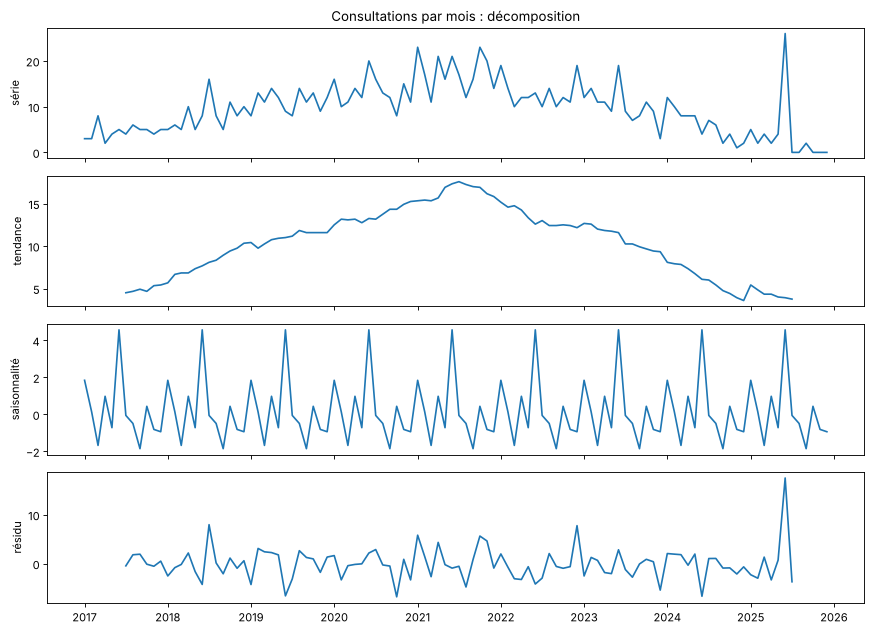

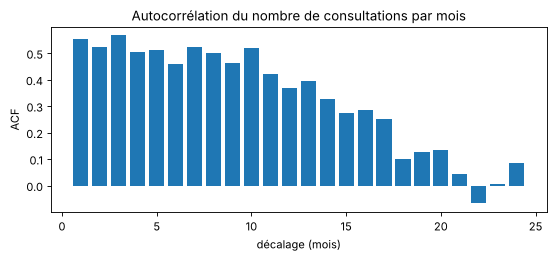

Mois avec le plus grand résidu : 2025-06 (résidu = 17.5)
Jours avec le plus de consultations :


,nb_consultations
encounter_start,
2025-06-20,22
2019-09-04,3
2021-07-18,3


Ce jour-là : 22 patients différents, heures : {'13:15': np.int64(17), '12:15': np.int64(4), '14:15': np.int64(1)}
Pour combien d'entre eux est-ce la dernière consultation ? 22


In [28]:
# Série temporelle : nombre de consultations par mois
serie = t["consultations"].set_index("encounter_start").resample("MS").size()
serie = serie["2017":"2025"]       # avant 2017 il n'y a presque rien

# Décomposition classique (cours 5, slide 16) avec une période de 12 mois
tendance = serie.rolling(12, center=True).mean()
saison = (serie - tendance).groupby(serie.index.month).mean()
composante_saison = pd.Series(saison.reindex(serie.index.month).values, index=serie.index)
residu = serie - tendance - composante_saison

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, (s, nom) in zip(axes, [(serie, "série"), (tendance, "tendance"), (composante_saison, "saisonnalité"), (residu, "résidu")]):
    ax.plot(s.index, s.values)
    ax.set_ylabel(nom)
axes[0].set_title("Consultations par mois : décomposition")
plt.tight_layout()
plt.show()

# Autocorrélation (ACF) : corrélation de Pearson entre la série et la série décalée de 'lag' mois
acf = pd.Series([serie.autocorr(lag) for lag in range(1, 25)], index=range(1, 25))
plt.figure(figsize=(8, 3))
plt.bar(acf.index, acf.values)
plt.xlabel("décalage (mois)")
plt.ylabel("ACF")
plt.title("Autocorrélation du nombre de consultations par mois")
plt.show()

# Le mois le plus "anormal" (plus gros résidu) : on regarde le jour en question
print("Mois avec le plus grand résidu :", residu.idxmax().strftime("%Y-%m"), f"(résidu = {residu.max():.1f})")
jours = t["consultations"]["encounter_start"].dt.date.value_counts()
print("Jours avec le plus de consultations :")
display(jours.head(3).to_frame("nb_consultations"))
jour = t["consultations"][t["consultations"]["encounter_start"].dt.date == jours.index[0]]
derniere = t["consultations"].groupby("patient_number")["encounter_start"].max()
print(f"Ce jour-là : {jour['patient_number'].nunique()} patients différents, heures :",
      dict(jour["encounter_start"].dt.strftime("%H:%M").value_counts()))
print("Pour combien d'entre eux est-ce la dernière consultation ?",
      (derniere.loc[jour["patient_number"]].dt.date == jours.index[0]).sum())

**Ce qu'on observe :**
* La **tendance** monte de 2017 à mi-2021 puis redescend. C'est sûrement lié à la façon dont la base a été construite (les patients sont inscrits progressivement puis les suivis se terminent), pas à une épidémie ou autre.
* L'**ACF** baisse doucement sans pic à 12 mois : il n'y a **pas de vraie saisonnalité**. La série est dominée par la tendance.
* La composante saisonnière a un pic en **juin**, mais il vient presque entièrement d'un seul mois : **juin 2025**, qui a de loin le plus gros résidu.
* En regardant ce mois de plus près : **22 patients différents** ont une consultation le **20/06/2025**, presque tous à 13h15, et c'est pour **tous** leur dernière consultation. Ça ressemble plus à un artefact (clôture de dossiers en masse, migration, date d'extraction...) qu'à de vraies visites. On le signale comme anomalie temporelle sans trop l'interpréter. C'est un bon exemple du cours : la saisonnalité calculée est fausse à cause d'une seule anomalie.

### 18.2 Est-ce que MRP-42 est donnée à intervalle régulier ?
Pour chaque patient qui a reçu MRP-42 plusieurs fois, on calcule le nombre de jours entre deux administrations. On trace aussi une frise : une ligne par patient, un point par administration.

Intervalle entre deux MRP-42 (jours) :


,count,mean,std,min,25%,50%,75%,max
performed_time,22.0,778.0,111.0,714.0,742.0,742.0,743.0,1176.0


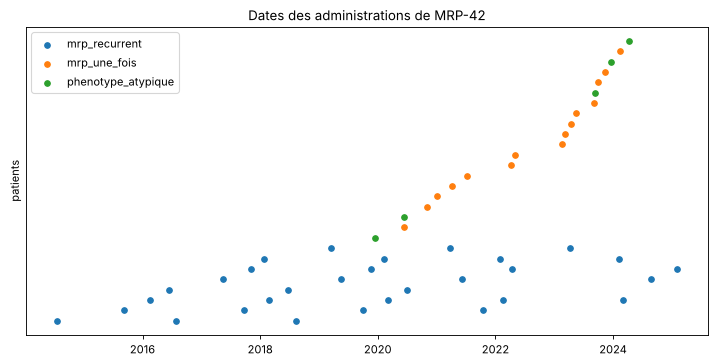

In [29]:
# Intervalle entre deux administrations de MRP-42 chez un même patient
mrp_trie = mrp.sort_values("performed_time")
intervalles = mrp_trie.groupby("patient_number")["performed_time"].diff().dt.days.dropna()
print("Intervalle entre deux MRP-42 (jours) :")
display(intervalles.describe().round(0).to_frame().T)

# frise chronologique des administrations par patient
plt.figure(figsize=(11, 5))
ordre = {pid: i for i, pid in enumerate(mrp_trie.groupby("patient_number")["performed_time"].min().sort_values().index)}
for prof, g in mrp_trie.groupby(mrp_trie["patient_number"].map(patients["profil"])):
    plt.scatter(g["performed_time"], g["patient_number"].map(ordre), label=prof, s=25)
plt.yticks([])
plt.ylabel("patients")
plt.legend()
plt.title("Dates des administrations de MRP-42")
plt.show()

**Ce qu'on observe :**
* L'intervalle entre deux MRP-42 chez un même patient est **très régulier** : médiane de **742 jours**, quartiles 742 – 743 jours, soit environ **2 ans** (avec un seul intervalle plus long, de 1 176 jours).
* Sur la frise, les dirigeants reçoivent MRP-42 depuis **2014**, tous les 2 ans, alors que les administrations « recherche » (une seule par patient) n'apparaissent qu'à partir de **fin 2019**. Le programme pour les dirigeants existe donc avant le protocole de recherche.
* Une telle régularité ressemble à un **protocole planifié** (une « cure » tous les 2 ans), pas à des soins décidés au cas par cas.

### 18.3 Signaux cardiaques
Chaque enregistrement a deux canaux (`a` et `b`). Pour estimer le rythme, on utilise l'**ACF** comme dans le cours : on corrèle le signal avec lui-même décalé de k points. Le premier pic de l'ACF (après 0,3 s, pour ne pas dépasser 200 bpm) donne la **période** d'un battement, donc le rythme : bpm = 60 × fs / décalage. La hauteur du pic dit à quel point le signal est **régulier**.

On fait ça sur les deux canaux. Si le cœur est « normal », les deux canaux doivent donner le même rythme.

On teste aussi la **détection d'anomalies par fenêtre glissante** (slide 20) : fenêtre Δt = 2 s, et un point est aberrant si son z-score modifié dans la fenêtre dépasse 3,5.

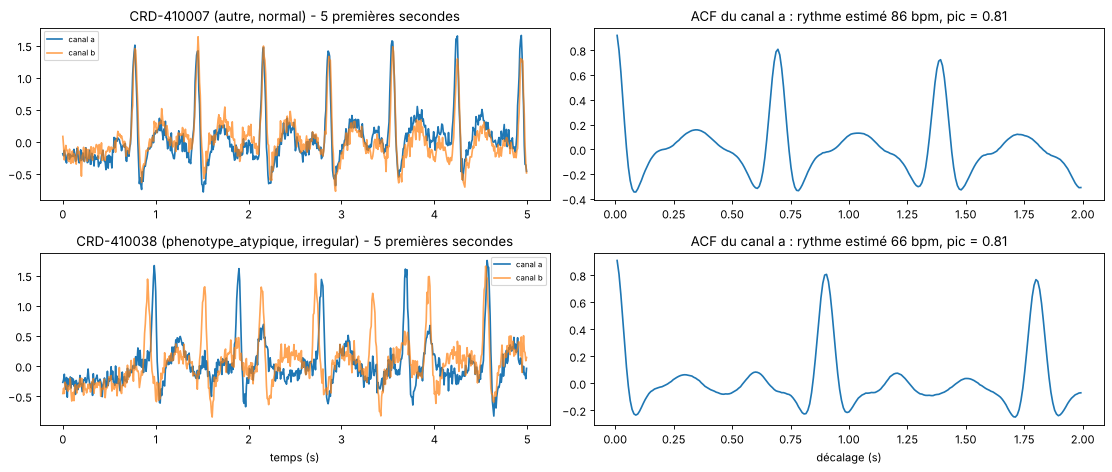

In [30]:
def acf_signal(x, lag_max):
    """ACF 'à la main' : corrélation de Pearson entre x et x décalé de k points."""
    x = x - x.mean()
    return np.array([np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, lag_max)])


def rythme_par_acf(x, fs):
    """Rythme cardiaque estimé (bpm) = 1er pic de l'ACF après 0,3 s (soit moins de 200 bpm)."""
    a = acf_signal(x, int(2 * fs))
    debut = int(0.3 * fs)
    lag = np.argmax(a[debut:]) + debut + 1
    return 60 * fs / lag, a[lag - 1], a


enr = t["enregistrements"].set_index("recording_id")
signaux = t["signaux"]

# deux exemples : un enregistrement "normal" et un enregistrement d'un patient atypique
exemples = ["CRD-410007", "CRD-410038"]
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for ligne, rid in enumerate(exemples):
    g = signaux[signaux["recording_id"] == rid]
    fs = enr.loc[rid, "sampling_rate_hz"]
    x = g["channel_a_normalized"].to_numpy()
    bpm, hauteur, a = rythme_par_acf(x, fs)
    prof = patients.loc[enr.loc[rid, "patient_number"], "profil"]
    cinq_sec = g["time_ms"] < 5000
    axes[ligne, 0].plot(g.loc[cinq_sec, "time_ms"] / 1000, g.loc[cinq_sec, "channel_a_normalized"], label="canal a")
    axes[ligne, 0].plot(g.loc[cinq_sec, "time_ms"] / 1000, g.loc[cinq_sec, "channel_b_normalized"], label="canal b", alpha=0.7)
    axes[ligne, 0].set_title(f"{rid} ({prof}, {enr.loc[rid, 'automated_interpretation']}) - 5 premières secondes")
    axes[ligne, 0].legend(fontsize=7)
    axes[ligne, 1].plot(np.arange(1, len(a) + 1) / fs, a)
    axes[ligne, 1].set_title(f"ACF du canal a : rythme estimé {bpm:.0f} bpm, pic = {hauteur:.2f}")
axes[1, 0].set_xlabel("temps (s)")
axes[1, 1].set_xlabel("décalage (s)")
plt.tight_layout()
plt.show()

In [31]:
def anomalies_fenetre(x, fs, fenetre_s=2, seuil=3.5):
    """Fenêtre glissante (cours 5, slide 20) : un point est aberrant si son z-score modifié,
    calculé avec les points de la fenêtre [t - dt/2, t + dt/2], dépasse le seuil."""
    s = pd.Series(x)
    w = int(fenetre_s * fs)
    med = s.rolling(w, center=True, min_periods=w // 2).median()
    eam = (s - med).abs().rolling(w, center=True, min_periods=w // 2).median()
    return int(((s - med).abs() / eam > seuil).sum())


lignes = []
for rid, g in signaux.groupby("recording_id"):
    fs = enr.loc[rid, "sampling_rate_hz"]
    bpm_a, pic_a, _ = rythme_par_acf(g["channel_a_normalized"].to_numpy(), fs)
    bpm_b, pic_b, _ = rythme_par_acf(g["channel_b_normalized"].to_numpy(), fs)
    pid = enr.loc[rid, "patient_number"]
    lignes.append({"recording_id": rid, "profil": patients.loc[pid, "profil"],
                   "contexte": enr.loc[rid, "recording_context"],
                   "bpm_acf_a": bpm_a, "bpm_acf_b": bpm_b,
                   "regularite_a": pic_a,
                   "pouls_peripherique": patients.loc[pid, "obs_PPULSE"],
                   "pct_points_aberrants": 100 * anomalies_fenetre(g["channel_a_normalized"].to_numpy(), fs) / len(g)})
resume_signaux = pd.DataFrame(lignes).set_index("recording_id")
resume_signaux["ecart_a_b"] = (resume_signaux["bpm_acf_a"] - resume_signaux["bpm_acf_b"]).abs()

display(resume_signaux.groupby("profil")[["bpm_acf_a", "pouls_peripherique", "ecart_a_b", "regularite_a", "pct_points_aberrants"]]
        .median().round(2).assign(nb=resume_signaux["profil"].value_counts()))
display(resume_signaux.groupby("contexte")[["regularite_a", "pct_points_aberrants"]].median().round(2))

# Les deux canaux donnent-ils le même rythme ? (écart de plus de 5 bpm = deux rythmes différents)
resume_signaux["deux_rythmes"] = resume_signaux["ecart_a_b"] > 5
display(pd.crosstab(resume_signaux["profil"], resume_signaux["deux_rythmes"]))
print("Enregistrements à deux rythmes, hors patients atypiques :")
display(resume_signaux[resume_signaux["deux_rythmes"] & (resume_signaux["profil"] != "phenotype_atypique")]
        [["profil", "contexte", "bpm_acf_a", "bpm_acf_b", "pouls_peripherique"]].round(1))

,bpm_acf_a,pouls_peripherique,ecart_a_b,regularite_a,pct_points_aberrants,nb
profil,,,,,,
autre,75.10,75.25,0.00,0.75,8.90,26
mrp_recurrent,69.93,69.55,0.00,0.79,8.54,4
mrp_une_fois,67.57,68.70,0.00,0.75,8.13,1
phenotype_atypique,69.77,71.60,17.19,0.80,8.67,13


,regularite_a,pct_points_aberrants
contexte,,
clinical_follow_up,0.76,9.63
post_exercise,0.75,9.00
rest,0.79,8.73
stress_assessment,0.72,8.12
technical_repeat,0.69,7.42


deux_rythmes,False,True
profil,,
autre,21,5
mrp_recurrent,4,0
mrp_une_fois,1,0
phenotype_atypique,4,9


Enregistrements à deux rythmes, hors patients atypiques :


,profil,contexte,bpm_acf_a,bpm_acf_b,pouls_peripherique
recording_id,,,,,
CRD-410002,autre,technical_repeat,34.3,82.2,67.4
CRD-410017,autre,technical_repeat,34.9,50.7,72.6
CRD-410028,autre,technical_repeat,36.6,53.6,72.5
CRD-410036,autre,post_exercise,197.4,192.3,49.3
CRD-410041,autre,technical_repeat,34.9,89.6,77.3


**Ce qu'on observe :**
* Sur l'exemple « normal » (`CRD-410007`), les deux canaux sont superposés et l'ACF a des pics bien réguliers. Sur l'exemple atypique (`CRD-410038`, patient `PAT-31065`), le canal b a des pics **en plus**, qui ne tombent pas au même moment que ceux du canal a.
* Le rythme du canal a correspond bien au **pouls périphérique** mesuré en consultation (médianes très proches pour tous les profils), donc la méthode ACF marche.
* Le résultat le plus fort : chez les patients atypiques, **9 enregistrements sur 13** donnent **deux rythmes différents** entre les canaux (en général ~70 bpm sur le canal a et ~90 – 100 bpm sur le canal b). Chez les autres patients, ça n'arrive presque que pour des `technical_repeat` avec un rythme estimé à ~35 bpm, c'est-à-dire la moitié du vrai rythme : un problème technique, pas une deuxième source. Le seul autre cas (`CRD-410036`, 197 bpm) est sûrement une erreur de notre estimation (l'ACF a pris une harmonique).
* Ça colle avec ce qu'on avait vu avant : pouls au cœur plus élevé qu'au poignet, et « pic thoracique secondaire » élevé. Une **deuxième source** de battement, plus rapide, qui ne se voit pas au poignet.
* La **fenêtre glissante**, en revanche, ne sépare rien : environ 8 – 9 % de points « aberrants » partout. Sur un ECG, ce sont les pics des battements eux-mêmes qui sont détectés. Le cours prévient que cette méthode est limitée sur les cas complexes, et c'est ce qu'on constate.

# Cours 6 : données textuelles

## 19. Notes cliniques

La table `clinical_notes` contient 30 textes (comptes rendus, consultations, suivis...). On suit la chaîne de pré-traitement du cours (slide 9) :
1. tout en **minuscules** ;
2. suppression de la **ponctuation** et des chiffres ;
3. suppression des **espaces** en trop ;
4. **tokenisation** (découpage en mots) ;
5. suppression des **stopwords** : on a pris la liste anglaise de `sklearn` et on a ajouté quelques mots trop fréquents ici (`patient`, `review`, `record`...) ;
6. au lieu de la lemmatisation (pas de `nltk` dans notre environnement), un **stemming très simple** : on enlève le « s » final des mots de plus de 4 lettres (`recordings` → `recording`). C'est grossier mais ça suffit pour regrouper singulier et pluriel.

Ensuite : **sac de mots** et **n-grammes** (unigrammes et bigrammes), puis **TF-IDF** pour trouver les mots clés de chaque note.

Avant : INDICATION Review of recurrent discordance between peripheral pulse measurements and apical recordings in a restricted patient, with comparison to the prior rhythm study.  TECHNIQUE Targeted thoracic  ...
Après : indication recurrent discordance peripheral pulse measurement apical recording restricted comparison prior rhythm study technique targeted thoracic ultrasound synchronized surface recording performed  ...


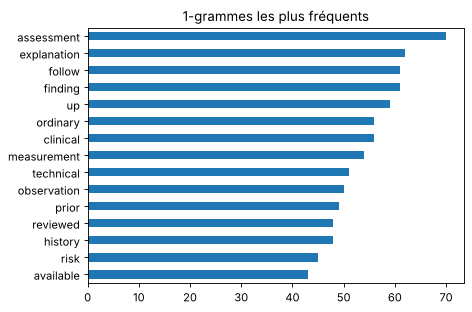

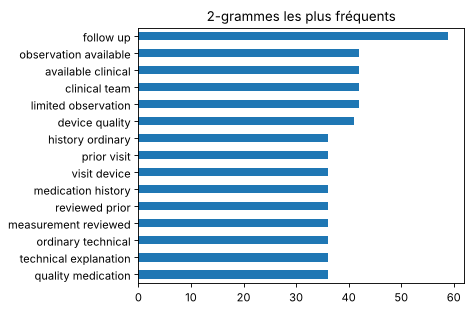

In [32]:
notes = t["notes"].copy()
notes["profil"] = notes["patient_number"].map(patients["profil"])

# stopwords anglais de sklearn + quelques mots trop fréquents dans ce corpus médical
stopwords = set(ENGLISH_STOP_WORDS) | {"patient", "patients", "review", "recorded", "record", "remains"}


def nettoyer_note(texte):
    """minuscules -> suppression ponctuation/chiffres -> espaces -> tokens -> stopwords -> pluriel simple."""
    texte = texte.lower()
    texte = re.sub(r"[^a-z\s-]", " ", texte)          # on garde lettres et tirets
    texte = re.sub(r"\s+", " ", texte).strip()
    tokens = [m for m in texte.split(" ") if m not in stopwords and len(m) > 2]
    # "stemming" très simple : on enlève le s final (recordings -> recording)
    tokens = [m[:-1] if m.endswith("s") and not m.endswith("ss") and len(m) > 4 else m for m in tokens]
    return " ".join(tokens)


notes["texte_propre"] = notes["text"].apply(nettoyer_note)
print("Avant :", notes["text"].iloc[0][:200].replace("\n", " "), "...")
print("Après :", notes["texte_propre"].iloc[0][:200], "...")

# sac de mots : les mots les plus fréquents, puis les bigrammes
for n_gram in [1, 2]:
    cv = CountVectorizer(ngram_range=(n_gram, n_gram))
    comptes = pd.Series(np.asarray(cv.fit_transform(notes["texte_propre"]).sum(axis=0)).ravel(),
                        index=cv.get_feature_names_out()).sort_values(ascending=False)
    comptes.head(15)[::-1].plot.barh(figsize=(6, 4), title=f"{n_gram}-grammes les plus fréquents")
    plt.tight_layout()
    plt.show()

In [33]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1)
M = tfidf.fit_transform(notes["texte_propre"])
vocab = tfidf.get_feature_names_out()

# les 5 termes les plus "caractéristiques" de chaque note
mots_cles = [", ".join(vocab[np.argsort(ligne.toarray().ravel())[::-1][:5]]) for ligne in M]
notes["mots_cles_tfidf"] = mots_cles
pd.set_option("display.max_colwidth", 120)
display(notes[["document_id", "patient_number", "profil", "document_type", "mots_cles_tfidf"]])

,document_id,patient_number,profil,document_type,mots_cles_tfidf
0,CLN-510027,PAT-31065,phenotype_atypique,imaging_report,"contractile, study, recording, spatially, dominant"
1,CLN-510055,PAT-31115,phenotype_atypique,specialist_consultation,"image, camera, independently, thermal, short interval"
2,CLN-510025,PAT-31065,phenotype_atypique,specialist_consultation,"public, attribute, resolution, consultation, does"
3,CLN-510064,PAT-31012,phenotype_atypique,follow_up_note,"ocular, vestibular, ocular tracking, recording, gait"
4,CLN-510107,PAT-31115,phenotype_atypique,clinical_summary,"occupational fatigue, fatigue assessment, assessment, occupational, fatigue"
5,CLN-510113,PAT-31215,phenotype_atypique,clinical_summary,"check, viral rhythm, viral, post, rhythm check"
6,CLN-510009,PAT-31012,phenotype_atypique,clinical_summary,"mobility follow, mobility, concern mobility, up limited, up"
7,CLN-510010,PAT-31037,phenotype_atypique,clinical_summary,"visual tracking, concern visual, tracking limited, tracking, visual"
8,CLN-510087,PAT-31044,mrp_recurrent,clinical_summary,"metabolic, metabolic risk, risk assessment, assessment, concern metabolic"
9,CLN-510081,PAT-31074,mrp_recurrent,clinical_summary,"pre travel, travel medical, medical clearance, medical, pre"


**Ce qu'on observe :**
* Les mots les plus fréquents (`assessment`, `follow`, `clinical`, `finding`...) sont du vocabulaire médical général. Les bigrammes sont un peu plus parlants.
* Avec le **TF-IDF**, on voit qu'il y a deux sortes de notes :
  * des notes « modèles » (`Clinical Summary 01`, `Imaging Report 07`...) dont les mots clés reviennent d'une note à l'autre (`metabolic risk`, `pre travel`, `viral rhythm`, `occupational fatigue`...), quel que soit le profil du patient ;
  * **4 notes longues et uniques**, toutes de patients **atypiques**, avec des mots clés très particuliers : `contractile`, `spatially`, `dominant` (deux sources de contraction dans le thorax), `camera`, `thermal` (problèmes de reconnaissance par caméra), `ocular`, `vestibular`, `gait` (démarche) et `public`, `attribute`, `resolution` (rapprochement avec une identité publique).

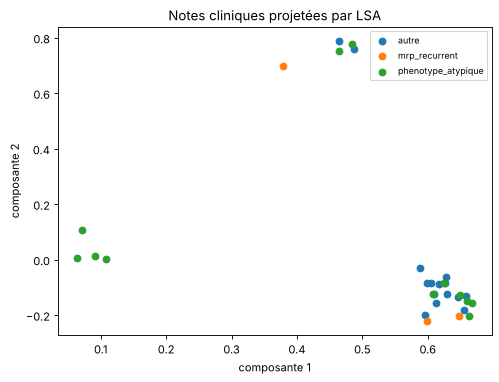

LSA composante 1 : assessment, follow up, up, follow, explanation, finding, clinical, encounter
LSA composante 2 : cardiac, contour, window repositioning, view, regular overall, recommended clinical, rhythm discordant, thoracic acquisition
LDA topic 0 : source, identity, peripheral, recording, public, consultation, study, repeated, image, imaging
LDA topic 1 : plan, symptom, reproduced, material, previously, annual, present, new, measure, tolerating
LDA topic 2 : assessment, explanation, up, follow, finding, clinical, ordinary, measurement, observation, technical


topic_lda,0,1,2
profil,,,
autre,0,0,15
mrp_recurrent,0,0,3
phenotype_atypique,3,1,8


In [34]:
# LSA : TF-IDF puis SVD en 2 dimensions
lsa = TruncatedSVD(n_components=2, random_state=SEED)
coord = lsa.fit_transform(M)
plt.figure(figsize=(7, 5))
for prof, g in notes.groupby("profil"):
    plt.scatter(coord[g.index, 0], coord[g.index, 1], label=prof)
plt.legend(fontsize=8)
plt.title("Notes cliniques projetées par LSA")
plt.xlabel("composante 1")
plt.ylabel("composante 2")
plt.show()
for i, comp in enumerate(lsa.components_):
    print(f"LSA composante {i + 1} :", ", ".join(vocab[np.argsort(comp)[::-1][:8]]))

# LDA : sur les comptages (pas sur le TF-IDF), avec k = 3 topics
cv = CountVectorizer()
comptes = cv.fit_transform(notes["texte_propre"])
lda = LatentDirichletAllocation(n_components=3, random_state=SEED)
topics = lda.fit_transform(comptes)
mots = cv.get_feature_names_out()
for i, comp in enumerate(lda.components_):
    print(f"LDA topic {i} :", ", ".join(mots[np.argsort(comp)[::-1][:10]]))
notes["topic_lda"] = topics.argmax(axis=1)
display(pd.crosstab(notes["profil"], notes["topic_lda"]))

In [35]:
# Une note parle d'un rapprochement avec une identité publique : on la cherche avec une regex
for _, ligne in notes.iterrows():
    trouve = re.search(r"public identity ([a-z]+ [a-z]+)", ligne["text"].lower())
    if trouve:
        print(ligne["document_id"], ligne["patient_number"], "->", trouve.group(1), "| profil :", ligne["profil"])

CLN-510025 PAT-31065 -> elias voss | profil : phenotype_atypique


**Topic modeling :**
* **LSA** (TF-IDF + SVD) : la 1ʳᵉ composante regroupe le vocabulaire commun des notes « modèles » ; la 2ᵉ isole des termes d'imagerie cardiaque. Sur la projection, on voit trois paquets : la majorité des notes (en bas à droite), les comptes rendus d'imagerie (en haut) et, complètement à l'écart à gauche, les **4 notes longues des patients atypiques**.
* **LDA** avec 3 topics : un topic regroupe `source`, `identity`, `peripheral`, `public`, `image`... et ne contient **que des notes de patients atypiques** (3 notes). Les deux autres topics correspondent au vocabulaire courant. On a pris k = 3 car avec seulement 30 documents, on ne voulait pas trop découper le corpus.
* Avec si peu de documents, le topic modeling est fragile : on s'en sert surtout pour confirmer ce que le TF-IDF montrait déjà.

**La note `CLN-510025`** (patient `PAT-31065`, profil atypique) dit explicitement que le numéro de patient peut être relié à l'**identité publique « Elias Voss »**, en combinant plusieurs attributs non secrets (tranche de date de naissance, région, adressage « dirigeant », historique d'établissement, fonction publique). La note reste très prudente : elle dit que le rapprochement est bien étayé, mais qu'aucune classification « biologique » n'est établie. On l'a trouvée avec une simple expression régulière.

# 20. Conclusion

### Ce qu'on a fait
On a repris le jeu de données `health/` du début à la fin en ajoutant à chaque cours les méthodes vues :
nettoyage et statistiques (cours 1), préparation, réduction de dimensions et clustering (cours 2), règles d'association et détection d'anomalies (cours 3), graphe et process mining (cours 4), analyse par lieu et séries temporelles (cours 5), et enfin analyse des notes cliniques (cours 6).

### Ce qu'on a trouvé
En croisant les méthodes, deux histoires ressortent, et à chaque fois **plusieurs méthodes indépendantes donnent le même résultat** :

**1. Un programme réservé à des dirigeants.** 8 patients, tous des personnes de pouvoir (chef de gouvernement, ministre, gouverneur, présidents de grands groupes), reçoivent la procédure **MRP-42** (« Targeted metabolic resilience administration ») :
* **tous les 2 ans environ** (≈ 742 jours, cf. 18.2), depuis 2014 ;
* toujours avec le même parcours `executive_health_review` → `specialist_procedure` (process mining, 16) ;
* toujours par **le même praticien** (`LIC-VLN-MED-1002`), en accès `restricted_specialist` (17) ;
* et ils ont un **âge biologique 12 à 17 ans plus bas** que leur âge réel (13 et 14).

La même procédure est donnée une seule fois, dans un cadre de **recherche**, à 20 autres patients à partir de fin 2019, et par plusieurs praticiens.

**2. Un groupe de patients au « phénotype » inhabituel.** Environ 30 patients cumulent des signes qui, pris un par un, pourraient être banals, mais qui apparaissent ensemble :
* un pouls au cœur bien plus élevé qu'au poignet et un « pic thoracique secondaire » (13, 14) ;
* dans les signaux cardiaques, **deux rythmes différents** sur les deux canaux, comme s'il y avait une deuxième source de battement (18.3) ;
* une démarche qui tangue mais un bon équilibre, des mouvements des yeux en partie indépendants, et des échecs de reconnaissance par caméra / thermique (14, notes du 19) ;
* un parcours de soins centré sur le cœur (16).

Ce groupe est retrouvé par K-means, l'agglomératif, DBSCAN, Isolation Forest, les communautés de Louvain et le topic modeling. Une note clinique relie l'un d'eux (`PAT-31065`) à une **identité publique, Elias Voss**.

### Nos limites
* **Corrélation n'est pas causalité** : on ne peut pas dire que MRP-42 rajeunit. Les patients suivis par le service « dirigeants » mais sans MRP-42 ont aussi un âge biologique plus bas (−11 ans). Il y a peut-être un effet du mode de vie ou un biais de sélection, et 8 patients c'est très peu.
* Les **seuils** (discrétisation pour Apriori, lift > 1,5, min_support, k du LDA...) ont été choisis par nous. Les chiffres exacts en dépendent, il faudrait tester d'autres valeurs pour vérifier que les conclusions tiennent.
* Les groupes K-means sont peu séparés (silhouette ≈ 0,17) : le « phénotype atypique » est plutôt un ensemble de signes qui vont ensemble qu'un groupe aux frontières nettes.
* Nettoyer, c'est choisir (cours 1) : par exemple la lecture des dates ambiguës en jour/mois est une hypothèse.
* Il n'y a pas de vraies coordonnées, donc la partie spatiale reste limitée.
* On n'a regardé que `health/`. Le nom « Elias Voss » apparaît aussi dans `public_records/` : ce serait la suite logique pour relier les deux histoires (est-ce que les patients atypiques ont un lien avec les dirigeants ou avec MRP-42 ?). Pour l'instant, avec nos données, on ne peut pas le dire.

### Ce qu'on retient sur la méthode
Ce qui a été le plus utile, c'est de **croiser les méthodes** : un résultat trouvé par une seule méthode (par exemple la saisonnalité de juin) peut être un artefact, alors qu'un résultat qui revient avec des approches très différentes (clustering, règles d'association, graphe, signal, texte) est beaucoup plus solide. On a aussi vu les limites de certaines méthodes sur nos données : le Heuristic Miner efface les alternances, la fenêtre glissante ne marche pas sur un ECG, et le LOF repère mal un petit groupe dense.